# Explainable AI and Racial Disparity in Recidivism Prediction: A Race-Blind Model Audit of the NIJ Recidivism Challenge Dataset

**Data source:** NIJ (National Institute of Justice) Recidivism Forecasting Challenge, *Full Dataset* (Georgia parolees; 3-year arrest-based recidivism outcome)

This notebook is the NIJ counterpart of the COMPAS notebook (`COMPASS_recidivism_xai_analysis_v02.ipynb`). It deliberately **mirrors the COMPAS pipeline step by step** (same models, same hyper-parameters, same 70/30 split and seed, same audit metrics) so that results from the two datasets are directly comparable, and it adds NIJ-specific analyses that make the second article more than a replication.

| Section | Content |
|---|---|
| 1 | Setup, configuration, utilities |
| 2 | Data loading, audit and cleaning (documented cleaning log) |
| 3 | Exploratory data analysis |
| 4 | Feature engineering, the four feature specifications, and the group-level feature-gap table |
| 5 | Race-blind predictive modeling vs. the incumbent Georgia risk score; 5-fold cross-validation |
| 6 | Explainable AI: SHAP analysis, functional-form check by race, SHAP decomposition of the group risk gap |
| 7 | Fairness audit: error-rate disparities with bootstrap CIs; unawareness diagnostics; Chouldechova decomposition |
| 8 | Calibration (overall, by race, and predictive parity of the incumbent score) |
| 9 | Classification-threshold sensitivity (model thresholds and incumbent cut-offs) |
| 10 | Robustness: official NIJ train/test split and repeated random splits |
| 11 | **Cross-dataset comparison: NIJ vs. COMPAS** (COMPAS side is recomputed live and checked against the published manuscript) |
| 12 | Auto-generated summary of findings, limitations, reproducibility metadata |

**Run notes.** Run the notebook top to bottom (*Kernel → Restart & Run All*). Tables are saved to `nij_outputs/tables/` and figures (300 dpi) to `nij_outputs/figures/` for direct use in the manuscript. If `xgboost` fails to import (e.g. a conda/pip version mismatch), the notebook falls back to scikit-learn's `HistGradientBoostingClassifier` and says so explicitly; to repair the install run `pip install --upgrade --force-reinstall xgboost` in a terminal and restart the kernel.

## 1. Setup and Configuration

In [1]:
import os, re, sys, json, time, platform, warnings, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score, accuracy_score, brier_score_loss, roc_curve, f1_score
from sklearn.calibration import calibration_curve
import shap

warnings.filterwarnings("ignore", category=FutureWarning)

# --- XGBoost guard -----------------------------------------------------------------
# A broken install raises ValueError (not ImportError), so catch every exception.
try:
    from xgboost import XGBClassifier
    XGB_AVAILABLE = True
except Exception as exc:
    XGB_AVAILABLE = False
    print(f"[WARNING] XGBoost could not be imported ({type(exc).__name__}). "
          "Falling back to sklearn HistGradientBoostingClassifier for the boosted-tree model.\n"
          "          Repair with: pip install --upgrade --force-reinstall xgboost  (then restart the kernel)")

# --- Configuration -----------------------------------------------------------------
SEED          = 42        # same as the COMPAS notebook
TEST_SIZE     = 0.30      # same 70/30 stratified split as the COMPAS notebook
THRESHOLD     = 0.50      # default decision threshold for the model-based classifiers
INC_CUTOFF    = 5         # incumbent score >= 5 labelled "high risk" (mirrors COMPAS decile >= 5)
N_BOOT        = 1000      # bootstrap replicates for disparity confidence intervals
PRIMARY_SPEC  = "Full"    # "History" | "Full" | "Full+PUMA"  -> drives SHAP / fairness / calibration / sweeps
INCLUDE_GENDER = True     # the COMPAS models also used sex as a predictor; set False to drop Gender
G1, G2        = "BLACK", "WHITE"   # the only two race categories in the NIJ file (order = ratio numerator, denominator)

RF_LABEL  = "Random Forest (race-blind)"
GB_LABEL  = "XGBoost (race-blind)" if XGB_AVAILABLE else "HistGradientBoosting (race-blind, XGBoost fallback)"
INC_LABEL = f"Georgia risk score (>= {INC_CUTOFF})"

OUT = Path("nij_outputs")
(OUT / "figures").mkdir(parents=True, exist_ok=True)
(OUT / "tables").mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 200)

# Same palette as the COMPAS notebook (African-American = orange, Caucasian = blue)
COLORS = {"BLACK": "#d55e00", "WHITE": "#0072b2", "African-American": "#d55e00", "Caucasian": "#0072b2"}

def savefig(name):
    plt.savefig(OUT / "figures" / f"{name}.png", dpi=300, bbox_inches="tight")

def save_table(frame, name, index=True):
    frame.to_csv(OUT / "tables" / f"{name}.csv", index=index)

print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| shap", shap.__version__, "| xgboost available:", XGB_AVAILABLE)

Python 3.12.3 | numpy 2.5.2 | pandas 3.0.5 | shap 0.52.0 | xgboost available: True


### 1.1 Utility functions

All fairness metrics are computed by the *same* helper functions for NIJ and COMPAS (Section 11), so the two datasets cannot differ because of implementation details.

* `confusion_rates` - FPR, FNR, PPV and flag rate from labels and binary predictions.
* `group_table` - per-group metrics for one classifier.
* `bootstrap_disparity` - group-stratified bootstrap CIs for FPR/FNR ratios and differences.
* `chouldechova_terms` - exact decomposition of the FPR ratio into base-rate, PPV and TPR components (Chouldechova, 2017).
* `calibration_gap`, `threshold_sweep`, `smd` - calibration, threshold sensitivity and standardized-mean-difference helpers.

In [2]:
def to_binary(series):
    # Robust Yes/No/True/False/1/0 -> {0,1}; raises if anything unmapped remains.
    mapping = {"yes": 1, "no": 0, "true": 1, "false": 0, "1": 1, "0": 0, "1.0": 1, "0.0": 0}
    out = series.astype(str).str.strip().str.lower().map(mapping)
    if out.isna().any():
        bad = series[out.isna()].unique()[:5]
        raise ValueError(f"Unmapped target values: {bad}")
    return out.astype(int)


def confusion_rates(y, pred):
    y, pred = np.asarray(y), np.asarray(pred)
    tp = int(((y == 1) & (pred == 1)).sum()); fp = int(((y == 0) & (pred == 1)).sum())
    tn = int(((y == 0) & (pred == 0)).sum()); fn = int(((y == 1) & (pred == 0)).sum())
    return dict(tp=tp, fp=fp, tn=tn, fn=fn,
                FPR=fp / (fp + tn) if (fp + tn) else np.nan,
                FNR=fn / (fn + tp) if (fn + tp) else np.nan,
                PPV=tp / (tp + fp) if (tp + fp) else np.nan,
                flag_rate=(tp + fp) / len(y) if len(y) else np.nan)


def group_table(model_name, y, pred, race, groups, proba=None):
    rows = []
    y, pred, race = np.asarray(y), np.asarray(pred), np.asarray(race)
    for g in groups:
        m = race == g
        r = confusion_rates(y[m], pred[m])
        auc = roc_auc_score(y[m], np.asarray(proba)[m]) if proba is not None else np.nan
        rows.append({"Model": model_name, "Group": g, "N": int(m.sum()), "Base rate": y[m].mean(),
                     "Flag rate": r["flag_rate"], "FPR": r["FPR"], "FNR": r["FNR"], "PPV": r["PPV"], "AUC (within group)": auc})
    return pd.DataFrame(rows)


def bootstrap_disparity(y, pred, race, g1, g2, n_boot=N_BOOT, seed=SEED):
    # Group-stratified bootstrap: resample within each group, preserving group sizes.
    rng = np.random.default_rng(seed)
    y, pred, race = np.asarray(y), np.asarray(pred), np.asarray(race)
    i1, i2 = np.where(race == g1)[0], np.where(race == g2)[0]
    draws = np.empty((n_boot, 4))
    for b in range(n_boot):
        s1, s2 = rng.choice(i1, len(i1)), rng.choice(i2, len(i2))
        r1, r2 = confusion_rates(y[s1], pred[s1]), confusion_rates(y[s2], pred[s2])
        draws[b] = [r1["FPR"] / r2["FPR"] if r2["FPR"] > 0 else np.nan,
                    r1["FNR"] / r2["FNR"] if r2["FNR"] > 0 else np.nan,
                    r1["FPR"] - r2["FPR"], r1["FNR"] - r2["FNR"]]
    lo, hi = np.nanpercentile(draws, [2.5, 97.5], axis=0)
    r1, r2 = confusion_rates(y[i1], pred[i1]), confusion_rates(y[i2], pred[i2])
    point = [r1["FPR"] / r2["FPR"], r1["FNR"] / r2["FNR"], r1["FPR"] - r2["FPR"], r1["FNR"] - r2["FNR"]]
    names = ["FPR ratio", "FNR ratio", "FPR diff", "FNR diff"]
    return pd.DataFrame({"estimate": point, "ci_low": lo, "ci_high": hi}, index=names)


def chouldechova_terms(y, pred, race, g1, g2):
    # Exact identity (Chouldechova, 2017):  FPR = [p/(1-p)] * [(1-PPV)/PPV] * TPR   for each group.
    # => FPR_g1/FPR_g2 = (base-rate odds ratio) x (PPV-odds ratio) x (TPR ratio).
    y, pred, race = np.asarray(y), np.asarray(pred), np.asarray(race)
    comp = {}
    for g in (g1, g2):
        m = race == g
        r = confusion_rates(y[m], pred[m]); p = y[m].mean()
        comp[g] = dict(odds=p / (1 - p), ppv_odds=(1 - r["PPV"]) / r["PPV"], tpr=1 - r["FNR"], fpr=r["FPR"])
    a, b = comp[g1], comp[g2]
    out = {"Base-rate odds ratio": a["odds"] / b["odds"],
           "PPV-odds ratio": a["ppv_odds"] / b["ppv_odds"],
           "TPR ratio": a["tpr"] / b["tpr"]}
    out["Product (= FPR ratio)"] = out["Base-rate odds ratio"] * out["PPV-odds ratio"] * out["TPR ratio"]
    out["FPR ratio (observed)"] = a["fpr"] / b["fpr"]
    return out


def calibration_gap(y, proba, n_bins):
    frac, mean_pred = calibration_curve(y, proba, n_bins=n_bins, strategy="quantile")
    return float(np.abs(frac - mean_pred).mean()), frac, mean_pred


def threshold_sweep(y, proba, race, g1, g2, thresholds):
    y, proba, race = np.asarray(y), np.asarray(proba), np.asarray(race)
    rows = []
    for t in thresholds:
        pred = (proba >= t).astype(int)
        r1 = confusion_rates(y[race == g1], pred[race == g1]); r2 = confusion_rates(y[race == g2], pred[race == g2])
        rows.append({"Threshold": round(float(t), 2), "Accuracy": accuracy_score(y, pred), "F1": f1_score(y, pred, zero_division=0),
                     f"FPR ({g1})": r1["FPR"], f"FPR ({g2})": r2["FPR"],
                     "FPR ratio": r1["FPR"] / r2["FPR"] if r2["FPR"] > 0 else np.nan,
                     "FPR diff": r1["FPR"] - r2["FPR"],
                     f"FNR ({g1})": r1["FNR"], f"FNR ({g2})": r2["FNR"],
                     "FNR ratio": r1["FNR"] / r2["FNR"] if r2["FNR"] > 0 else np.nan,
                     "min FP count": min(r1["fp"], r2["fp"])})
    sw = pd.DataFrame(rows)
    sw["Stable"] = sw["min FP count"] >= 30   # ratios are unreliable when a cell has < 30 false positives
    return sw


def smd(x, race, g1, g2):
    # Standardized mean difference (g1 - g2) using the pooled SD.
    x, race = np.asarray(x, dtype=float), np.asarray(race)
    a, b = x[race == g1], x[race == g2]
    pooled = np.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)
    return (a.mean() - b.mean()) / pooled if pooled > 0 else np.nan


def wilson_ci(k, n):
    ci = stats.binomtest(int(k), int(n)).proportion_ci(method="wilson")
    return ci.low, ci.high

## 2. Data Loading, Audit and Cleaning

The NIJ file is read from a local copy when present. If it is missing, the loader tries the official NIJ/OJP open-data endpoint and then a public mirror of the same file, and saves a local copy so that later runs are offline. (The official endpoint can be blocked on some networks; if all sources fail, download the *Full Dataset* CSV manually from the NIJ Recidivism Challenge page and place it next to this notebook.)

In [3]:
LOCAL_FILENAMES = ["NIJ_s_Recidivism_Challenge_Full_Dataset.csv", "nij-challenge2021_full_dataset.csv"]
REMOTE_SOURCES = [
    ("official OJP open data", "https://data.ojp.usdoj.gov/api/views/ynf5-u8nk/rows.csv?accessType=DOWNLOAD"),
    ("public GitHub mirror",   "https://raw.githubusercontent.com/RyanBalech/recidivism-forecasting-analysis/main/data/nij-challenge2021_full_dataset.csv"),
]

def load_nij():
    for fname in LOCAL_FILENAMES:
        if os.path.exists(fname):
            print(f"Loaded local file: {fname}")
            return pd.read_csv(fname)
    for label, url in REMOTE_SOURCES:
        try:
            with urllib.request.urlopen(url, timeout=60) as resp:
                data = pd.read_csv(resp)
            data.to_csv(LOCAL_FILENAMES[0], index=False)
            print(f"Downloaded from {label}; saved local copy as {LOCAL_FILENAMES[0]}")
            return data
        except Exception as exc:
            print(f"  could not use {label}: {type(exc).__name__}")
    raise FileNotFoundError("NIJ file not found locally and all download sources failed - see the note above.")

raw = load_nij()
print("Raw shape:", raw.shape)

EXPECTED = {"ID", "Gender", "Race", "Age_at_Release", "Supervision_Risk_Score_First", "Recidivism_Within_3years",
            "Recidivism_Arrest_Year1", "Recidivism_Arrest_Year2", "Recidivism_Arrest_Year3", "Training_Sample"}
missing_cols = EXPECTED - set(raw.columns)
assert not missing_cols, f"Unexpected file layout; missing columns: {missing_cols}"
raw.head(3)

Loaded local file: NIJ_s_Recidivism_Challenge_Full_Dataset.csv
Raw shape: (25835, 54)


,ID,Gender,Race,Age_at_Release,Residence_PUMA,Gang_Affiliated,Supervision_Risk_Score_First,Supervision_Level_First,Education_Level,Dependents,Prison_Offense,Prison_Years,Prior_Arrest_Episodes_Felony,Prior_Arrest_Episodes_Misd,Prior_Arrest_Episodes_Violent,Prior_Arrest_Episodes_Property,Prior_Arrest_Episodes_Drug,_v1,Prior_Arrest_Episodes_DVCharges,Prior_Arrest_Episodes_GunCharges,Prior_Conviction_Episodes_Felony,Prior_Conviction_Episodes_Misd,Prior_Conviction_Episodes_Viol,Prior_Conviction_Episodes_Prop,Prior_Conviction_Episodes_Drug,_v2,_v3,_v4,Prior_Revocations_Parole,Prior_Revocations_Probation,Condition_MH_SA,Condition_Cog_Ed,Condition_Other,Violations_ElectronicMonitoring,Violations_Instruction,Violations_FailToReport,Violations_MoveWithoutPermission,Delinquency_Reports,Program_Attendances,Program_UnexcusedAbsences,Residence_Changes,Avg_Days_per_DrugTest,DrugTests_THC_Positive,DrugTests_Cocaine_Positive,DrugTests_Meth_Positive,DrugTests_Other_Positive,Percent_Days_Employed,Jobs_Per_Year,Employment_Exempt,Recidivism_Within_3years,Recidivism_Arrest_Year1,Recidivism_Arrest_Year2,Recidivism_Arrest_Year3,Training_Sample
0,1,M,BLACK,43-47,16,No,3.0,Standard,At least some college,3 or more,Drug,More than 3 years,6,6 or more,1,3,3,4,No,No,3 or more,3,No,2,2 or more,No,No,No,No,No,Yes,Yes,No,No,No,No,No,0,6,0,2,612.000000,0.000000,0.0,0.000000,0.0,0.488562,0.44761,No,No,No,No,No,1
1,2,M,BLACK,33-37,16,No,6.0,Specialized,Less than HS diploma,1,Violent/Non-Sex,More than 3 years,7,6 or more,3 or more,0,3,5 or more,Yes,No,3 or more,4 or more,Yes,0,2 or more,Yes,Yes,Yes,No,No,No,No,No,No,Yes,No,No,4 or more,0,0,2,35.666667,0.000000,0.0,0.000000,0.0,0.425234,2.00000,No,Yes,No,No,Yes,1
2,3,M,BLACK,48 or older,24,No,7.0,High,At least some college,3 or more,Drug,1-2 years,6,6 or more,3 or more,2,2,5 or more,Yes,No,3 or more,2,Yes,1,2 or more,No,Yes,No,No,No,Yes,Yes,No,No,Yes,No,Yes,4 or more,6,0,0,93.666667,0.333333,0.0,0.166667,0.0,0.000000,0.00000,No,Yes,No,Yes,No,1


### 2.1 Cleaning log

Every row-level decision is recorded in `cleaning_log` (this replaces the ad-hoc `cleaning_metadata` dictionary of the earlier draft) so that the sample flow can be reported verbatim in the manuscript's methods section.

* **Outcome.** `Recidivism_Within_3years` is stored as `Yes`/`No` text and is converted to 0/1 with a strict mapping (any unmapped value raises an error rather than silently becoming `NaN`).
* **Incumbent risk score.** Rows with a missing `Supervision_Risk_Score_First` are excluded, exactly as COMPAS rows with a missing `score_text` were excluded in the COMPAS analysis. The earlier draft instead filled missing scores with 0, which silently classified those people as "low risk". Excluding them keeps the model-vs-incumbent comparison on a single common sample.
* **No other rows are dropped.** Missing predictor values are handled by explicit sentinel encoding in Section 4 (missingness is structural in this file, see below), not by deleting rows.

In [4]:
cleaning_log = []
def log_step(action, n_before, n_after, rationale):
    cleaning_log.append({"Step": len(cleaning_log) + 1, "Action": action, "Rows before": n_before,
                         "Rows after": n_after, "Rows removed": n_before - n_after, "Rationale": rationale})

df = raw.copy()
assert df["ID"].is_unique, "Duplicate IDs found"
assert set(df["Race"].unique()) <= {"BLACK", "WHITE"}, f"Unexpected race categories: {df['Race'].unique()}"

# 1) outcome must be present
n0 = len(df)
df = df[df["Recidivism_Within_3years"].notna()]
log_step("Drop rows with missing 3-year outcome", n0, len(df), "A supervised target is required.")

# 2) strict binary conversion of the outcome and of the yearly arrest indicators
for col in ["Recidivism_Within_3years", "Recidivism_Arrest_Year1", "Recidivism_Arrest_Year2", "Recidivism_Arrest_Year3"]:
    df[col] = to_binary(df[col])
any_year = df[["Recidivism_Arrest_Year1", "Recidivism_Arrest_Year2", "Recidivism_Arrest_Year3"]].max(axis=1)
assert (any_year == df["Recidivism_Within_3years"]).all(), "3-year outcome inconsistent with yearly indicators"
log_step("Convert Yes/No outcome columns to 0/1", len(df), len(df),
         "Strict mapping; verified Recidivism_Within_3years == any(Year1..Year3).")

# 3) incumbent risk score must be present (parallels dropping COMPAS rows with missing score_text)
excluded = df[df["Supervision_Risk_Score_First"].isna()]
n1 = len(df)
df = df[df["Supervision_Risk_Score_First"].notna()].reset_index(drop=True)
log_step("Drop rows with missing Supervision_Risk_Score_First", n1, len(df),
         f"Incumbent-score benchmark needs a score; excluded rows' 3-yr recidivism rate = {excluded['Recidivism_Within_3years'].mean():.3f} "
         f"(retained rows: {df['Recidivism_Within_3years'].mean():.3f}).")

cleaning_log = pd.DataFrame(cleaning_log)
save_table(cleaning_log, "table_cleaning_log", index=False)
display(cleaning_log)

y = df["Recidivism_Within_3years"].astype(int)
race = df["Race"]
print(f"\nAnalytic sample: N = {len(df):,}   |   3-year recidivism rate = {y.mean():.3f}")
print("\nRace distribution (%):"); print((race.value_counts(normalize=True) * 100).round(2).to_string())
print("\nGender distribution (%):"); print((df["Gender"].value_counts(normalize=True) * 100).round(2).to_string())

,Step,Action,Rows before,Rows after,Rows removed,Rationale
0,1,Drop rows with missing 3-year outcome,25835,25835,0,A supervised target is required.
1,2,Convert Yes/No outcome columns to 0/1,25835,25835,0,Strict mapping; verified Recidivism_Within_3ye...
2,3,Drop rows with missing Supervision_Risk_Score_...,25835,25360,475,Incumbent-score benchmark needs a score; exclu...



Analytic sample: N = 25,360   |   3-year recidivism rate = 0.576

Race distribution (%):
Race
BLACK    57.44
WHITE    42.56

Gender distribution (%):
Gender
M    87.76
F    12.24


### 2.2 Missing-value structure

Missingness in this file is largely **structural**, not random, which is why the earlier `fillna(0)` on a numeric-only subset was inappropriate:

* `Gang_Affiliated` is missing for *every* female record (it is only recorded for males).
* The drug-test variables are missing when no drug test was administered.
* `Prison_Offense` has a genuine "not recorded" category.

These patterns are informative, so Section 4 encodes them explicitly (sentinel value `-1`, or a `Missing` dummy for `Prison_Offense`) instead of imputing.

In [5]:
miss = df.isna().sum()
miss = miss[miss > 0].to_frame("Missing (n)")
miss["Missing (%)"] = (miss["Missing (n)"] / len(df) * 100).round(2)
display(miss)
print("Gang_Affiliated missing vs Gender:")
display(pd.crosstab(df["Gender"], df["Gang_Affiliated"].isna(), rownames=["Gender"], colnames=["Gang missing"]))
save_table(miss, "table_missingness")

,Missing (n),Missing (%)
Gang_Affiliated,3104,12.24
Supervision_Level_First,1405,5.54
Prison_Offense,3230,12.74
Avg_Days_per_DrugTest,5882,23.19
DrugTests_THC_Positive,4960,19.56
DrugTests_Cocaine_Positive,4960,19.56
DrugTests_Meth_Positive,4960,19.56
DrugTests_Other_Positive,4960,19.56
Percent_Days_Employed,460,1.81
Jobs_Per_Year,803,3.17


Gang_Affiliated missing vs Gender:


Gang missing,False,True
Gender,,
F,0,3104
M,22256,0


### 2.3 Table 1 - Sample characteristics by race

`Recidivism arrest in year k` are *year-specific* indicators (the 3-year outcome is their union). The 95% interval on the recidivism rate is a Wilson interval.

In [6]:
def prior_felony_numeric(frame):
    return frame["Prior_Arrest_Episodes_Felony"].astype(str).str.extract(r"(\d+)")[0].astype(float)

tmp = df.assign(_prior_felony=prior_felony_numeric(df))
rows = []
for g in [G1, G2]:
    s = tmp[tmp["Race"] == g]
    lo, hi = wilson_ci(s["Recidivism_Within_3years"].sum(), len(s))
    rows.append({"Group": g, "N": len(s), "Share of sample (%)": 100 * len(s) / len(tmp),
                 "Male (%)": 100 * (s["Gender"] == "M").mean(),
                 "3-yr recidivism rate": s["Recidivism_Within_3years"].mean(),
                 "3-yr rate, 95% CI": f"[{lo:.3f}, {hi:.3f}]",
                 "Arrest in year 1": s["Recidivism_Arrest_Year1"].mean(),
                 "Arrest in year 2": s["Recidivism_Arrest_Year2"].mean(),
                 "Arrest in year 3": s["Recidivism_Arrest_Year3"].mean(),
                 "Mean prior felony arrests (capped at 10)": s["_prior_felony"].mean(),
                 "Mean % days employed": s["Percent_Days_Employed"].mean(),
                 "Mean Georgia risk score (1-10)": s["Supervision_Risk_Score_First"].mean(),
                 f"Flagged high-risk (score>={INC_CUTOFF}, %)": 100 * (s["Supervision_Risk_Score_First"] >= INC_CUTOFF).mean()})
table1 = pd.DataFrame(rows).set_index("Group").T
display(table1)
save_table(table1, "table1_sample_characteristics")

# Test of the base-rate difference between the two groups
ct = pd.crosstab(df["Race"], df["Recidivism_Within_3years"])
chi2, p_chi, _, _ = stats.chi2_contingency(ct, correction=False)
br = df.groupby("Race")["Recidivism_Within_3years"].mean()
print(f"Base-rate gap ({G1} - {G2}) = {100*(br[G1]-br[G2]):.2f} percentage points;  chi-square = {chi2:.1f},  p = {p_chi:.2e}")

Group,BLACK,WHITE
N,14567,10793
Share of sample (%),57.440852,42.559148
Male (%),92.757603,81.015473
3-yr recidivism rate,0.585158,0.562865
"3-yr rate, 95% CI","[0.577, 0.593]","[0.553, 0.572]"
Arrest in year 1,0.309741,0.280645
Arrest in year 2,0.173268,0.181877
Arrest in year 3,0.102149,0.100343
Mean prior felony arrests (capped at 10),5.696094,5.797369
Mean % days employed,0.441853,0.543422


Base-rate gap (BLACK - WHITE) = 2.23 percentage points;  chi-square = 12.6,  p = 3.83e-04


## 3. Exploratory Data Analysis

Four views that matter for the fairness analysis: (a) observed base rates by race, (b) the distribution of prior felony arrests (the NIJ analogue of `priors_count` in the COMPAS study), (c) employment during supervision, and (d) when the first re-arrest occurs.

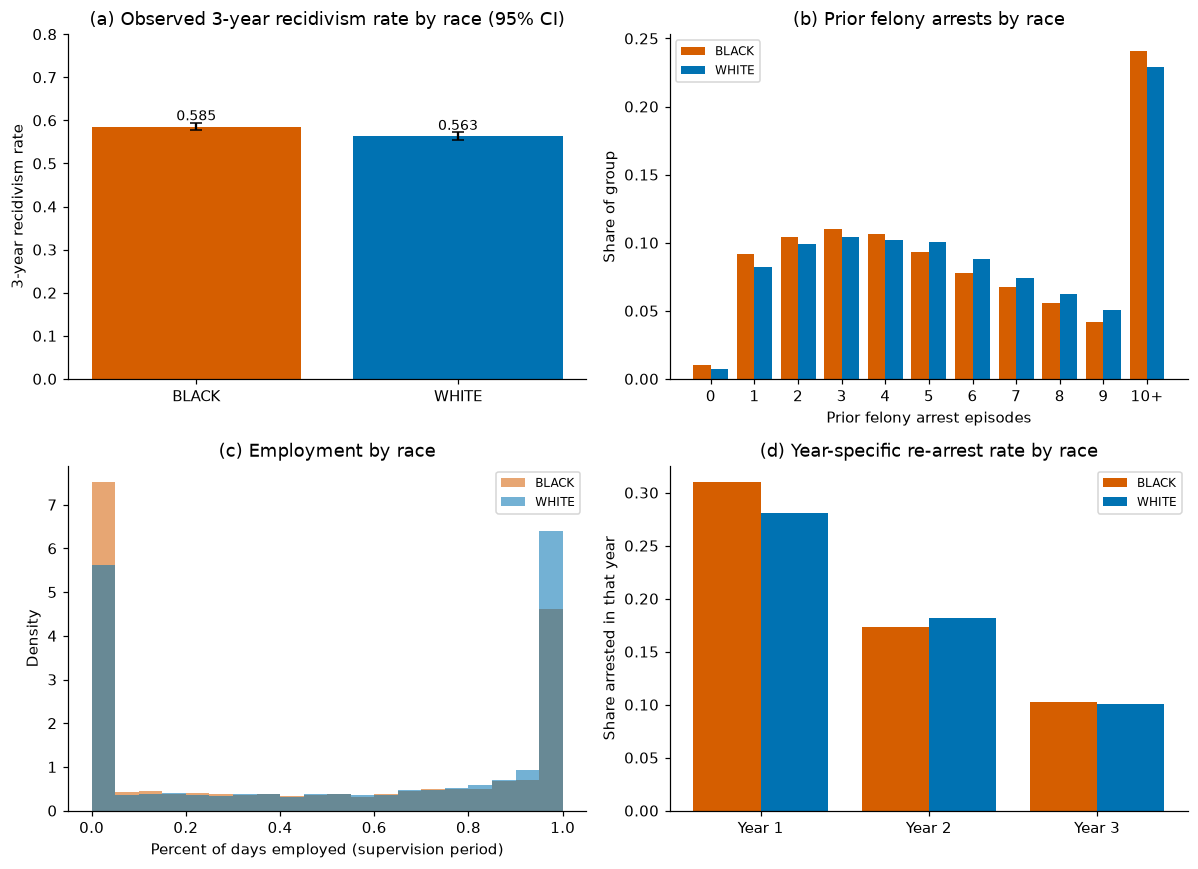

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

# (a) base rate by race with Wilson CI
ax = axes[0, 0]
for i, g in enumerate([G1, G2]):
    s = df[df["Race"] == g]["Recidivism_Within_3years"]
    lo, hi = wilson_ci(s.sum(), len(s)); m = s.mean()
    ax.bar(i, m, color=COLORS[g], yerr=[[m - lo], [hi - m]], capsize=4)
    ax.text(i, m + 0.015, f"{m:.3f}", ha="center", fontsize=9)
ax.set_xticks([0, 1]); ax.set_xticklabels([G1, G2]); ax.set_ylim(0, 0.8)
ax.set_ylabel("3-year recidivism rate"); ax.set_title("(a) Observed 3-year recidivism rate by race (95% CI)")

# (b) prior felony arrests by race
ax = axes[0, 1]
pf = df.assign(pf=prior_felony_numeric(df))
dist = pf.groupby("Race")["pf"].value_counts(normalize=True).unstack(0)
dist.index = dist.index.astype(int)
dist = dist.reindex(range(0, 11)).fillna(0)
w = 0.4
ax.bar(dist.index - w / 2, dist[G1], width=w, color=COLORS[G1], label=G1)
ax.bar(dist.index + w / 2, dist[G2], width=w, color=COLORS[G2], label=G2)
ax.set_xticks(range(0, 11)); ax.set_xticklabels([str(i) if i < 10 else "10+" for i in range(11)])
ax.set_xlabel("Prior felony arrest episodes"); ax.set_ylabel("Share of group")
ax.set_title("(b) Prior felony arrests by race"); ax.legend(fontsize=8)

# (c) employment during supervision
ax = axes[1, 0]
for g in [G1, G2]:
    ax.hist(df.loc[df["Race"] == g, "Percent_Days_Employed"].dropna(), bins=20, alpha=0.55, density=True, color=COLORS[g], label=g)
ax.set_xlabel("Percent of days employed (supervision period)"); ax.set_ylabel("Density")
ax.set_title("(c) Employment by race"); ax.legend(fontsize=8)

# (d) year-specific re-arrest
ax = axes[1, 1]
yrs = ["Recidivism_Arrest_Year1", "Recidivism_Arrest_Year2", "Recidivism_Arrest_Year3"]
rates = df.groupby("Race")[yrs].mean().loc[[G1, G2]]
xs = np.arange(3)
ax.bar(xs - w / 2, rates.loc[G1], width=w, color=COLORS[G1], label=G1)
ax.bar(xs + w / 2, rates.loc[G2], width=w, color=COLORS[G2], label=G2)
ax.set_xticks(xs); ax.set_xticklabels(["Year 1", "Year 2", "Year 3"]); ax.set_ylabel("Share arrested in that year")
ax.set_title("(d) Year-specific re-arrest rate by race"); ax.legend(fontsize=8)

plt.tight_layout(); savefig("fig1_eda"); plt.show()

## 4. Feature Engineering and Feature Specifications

The earlier draft kept only columns that pandas had already parsed as numeric. Because most NIJ variables are text categories (`"3 or more"`, `"Yes"`, `"23-27"` ...), that silently discarded roughly 40 of the 50 predictors. Here every predictor is encoded explicitly:

* ordered categories (`Age_at_Release`, `Prison_Years`, `Education_Level`) -> ordinal codes;
* top-coded counts (`"10 or more"`, `"3 or more"` ...) -> the leading integer;
* `Yes`/`No` -> 1/0;
* `Prison_Offense` -> one-hot with an explicit `Missing` level;
* structural missing values -> sentinel `-1` (no statistics are fitted on the data, so there is no train/test leakage from imputation).

**Never used as predictors:** `Race`, `ID`, all `Recidivism_*` columns, `Training_Sample`, and the incumbent tool's own outputs `Supervision_Risk_Score_First` and `Supervision_Level_First`. The incumbent score is withheld from the models and used only as the benchmark, exactly as the COMPAS `decile_score` was in the COMPAS study. (The earlier draft used the risk score as a model input *and* as the comparison benchmark, which is circular.)

### Four specifications

| Specification | Contents | Purpose |
|---|---|---|
| **History** | age at release, prison term, prison offense, prior arrests / convictions / revocations, gender | closest analogue of the COMPAS predictors (age, prior record, charge, sex) |
| **Full** | History + four unlabeled prior-record fields (`_v1`-`_v4`) + education, dependents, gang affiliation, supervision conditions + supervision-period behavior (violations, delinquency reports, programs, residence changes, drug tests, employment) | the usual NIJ-challenge style model |
| **Full+PUMA** | Full + one-hot `Residence_PUMA` (area of residence) | tests a geographic proxy channel for race |
| **Full+Race (diagnostic)** | Full + `Race` | *diagnostic only*: what changes if race is made available to the model? Not a recommended model. |

`PRIMARY_SPEC` (Section 1) selects which specification drives the SHAP, audit, calibration and threshold sections. All four are always compared in Sections 5 and 7.

> **Caution on supervision-period variables.** Violations, delinquency reports, program attendance, residence changes, drug tests and employment are measured *during supervision*, i.e. partly inside the window in which the outcome is observed. Their temporal ordering relative to the re-arrest should be checked against the NIJ data dictionary before the *Full* results are described as "prediction at release". The **History** specification is the conservative, release-time check. The four columns `_v1`-`_v4` have anonymized headers in the public file; their positions suggest prior-record fields, but this should be confirmed against the data dictionary.

In [8]:
ORDINAL_LEVELS = {
    "Age_at_Release":  ["18-22", "23-27", "28-32", "33-37", "38-42", "43-47", "48 or older"],
    "Prison_Years":    ["Less than 1 year", "1-2 years", "Greater than 2 to 3 years", "More than 3 years"],
    "Education_Level": ["Less than HS diploma", "High School Diploma", "At least some college"],
}

def encode_column(frame, col):
    s = frame[col]
    if col in ORDINAL_LEVELS:
        mapping = {lvl: i for i, lvl in enumerate(ORDINAL_LEVELS[col])}
        out = s.map(mapping)
        assert out.notna().all(), f"Unmapped levels in {col}: {set(s.unique()) - set(mapping)}"
        return out.astype(float)
    if pd.api.types.is_numeric_dtype(s):
        return s.astype(float)
    if set(s.dropna().unique()) <= {"Yes", "No"}:
        return s.map({"No": 0, "Yes": 1}).astype(float)
    out = s.astype(str).str.extract(r"(\d+)")[0].astype(float)     # "3 or more" -> 3, "10 or more" -> 10
    out[s.isna()] = np.nan
    return out

HISTORY_COLS = ["Age_at_Release", "Prison_Years",
                "Prior_Arrest_Episodes_Felony", "Prior_Arrest_Episodes_Misd", "Prior_Arrest_Episodes_Violent",
                "Prior_Arrest_Episodes_Property", "Prior_Arrest_Episodes_Drug",
                "Prior_Arrest_Episodes_DVCharges", "Prior_Arrest_Episodes_GunCharges",
                "Prior_Conviction_Episodes_Felony", "Prior_Conviction_Episodes_Misd", "Prior_Conviction_Episodes_Viol",
                "Prior_Conviction_Episodes_Prop", "Prior_Conviction_Episodes_Drug",
                "Prior_Revocations_Parole", "Prior_Revocations_Probation"]

SUPERVISION_PERIOD_COLS = ["Violations_ElectronicMonitoring", "Violations_Instruction", "Violations_FailToReport",
                           "Violations_MoveWithoutPermission", "Delinquency_Reports", "Program_Attendances",
                           "Program_UnexcusedAbsences", "Residence_Changes", "Avg_Days_per_DrugTest",
                           "DrugTests_THC_Positive", "DrugTests_Cocaine_Positive", "DrugTests_Meth_Positive",
                           "DrugTests_Other_Positive", "Percent_Days_Employed", "Jobs_Per_Year", "Employment_Exempt"]

BACKGROUND_COLS = ["_v1", "_v2", "_v3", "_v4", "Education_Level", "Dependents", "Gang_Affiliated",
                   "Condition_MH_SA", "Condition_Cog_Ed", "Condition_Other"]

FULL_COLS = HISTORY_COLS + BACKGROUND_COLS + SUPERVISION_PERIOD_COLS
assert all(c in df.columns for c in FULL_COLS), [c for c in FULL_COLS if c not in df.columns]

FORBIDDEN_PREFIXES = ("Recidivism", "Supervision_Risk", "Supervision_Level", "Training", "ID")

def make_features(frame, columns, gender=INCLUDE_GENDER, puma=False, include_race=False):
    X = pd.DataFrame({c: encode_column(frame, c) for c in columns}).fillna(-1.0)   # sentinel for structural missingness
    if gender:
        X["Gender_M"] = (frame["Gender"] == "M").astype(float)
    X = pd.concat([X, pd.get_dummies(frame["Prison_Offense"].fillna("Missing"), prefix="Offense").astype(float)], axis=1)
    if puma:
        X = pd.concat([X, pd.get_dummies(frame["Residence_PUMA"], prefix="PUMA").astype(float)], axis=1)
    if include_race:
        X["Race_Black"] = (frame["Race"] == "BLACK").astype(float)
    # leakage / protected-attribute guard
    bad = [c for c in X.columns if c.startswith(FORBIDDEN_PREFIXES)]
    assert not bad, f"Forbidden columns in feature matrix: {bad}"
    if not include_race:
        assert not any(c.startswith("Race") for c in X.columns), "Race leaked into a race-blind specification"
    assert X.notna().all().all(), "NaN remained after encoding"
    return X

SPEC_FEATURES = {
    "History":                make_features(df, HISTORY_COLS),
    "Full":                   make_features(df, FULL_COLS),
    "Full+PUMA":              make_features(df, FULL_COLS, puma=True),
    "Full+Race (diagnostic)": make_features(df, FULL_COLS, include_race=True),
}
assert PRIMARY_SPEC in SPEC_FEATURES, f"PRIMARY_SPEC must be one of {list(SPEC_FEATURES)}"

spec_table = pd.DataFrame({"Features (n)": {k: v.shape[1] for k, v in SPEC_FEATURES.items()},
                           "Race as input": {k: ("YES (diagnostic)" if "Race" in k else "no") for k in SPEC_FEATURES}})
display(spec_table)
print(f"PRIMARY_SPEC = '{PRIMARY_SPEC}'  ({SPEC_FEATURES[PRIMARY_SPEC].shape[1]} features)")

,Features (n),Race as input
History,23,no
Full,49,no
Full+PUMA,74,no
Full+Race (diagnostic),50,YES (diagnostic)


PRIMARY_SPEC = 'Full'  (49 features)


### 4.1 Group-level feature gaps (the proxy channel)

In the COMPAS study the disparity traced back to unequal distributions of `priors_count` across groups. The analogous question here is: **which model inputs differ most between the two groups?** The table reports the standardized mean difference (SMD = (mean<sub>BLACK</sub> - mean<sub>WHITE</sub>) / pooled SD) for every input of the primary specification. Values near 0 mean the two groups look alike on that input; |SMD| of about 0.2 is conventionally small, 0.5 medium. (Features coded with the `-1` sentinel are shown as coded.)

In [9]:
X_primary_all = SPEC_FEATURES[PRIMARY_SPEC]
gap = pd.DataFrame({"SMD (BLACK - WHITE)": {c: smd(X_primary_all[c], race, G1, G2) for c in X_primary_all.columns},
                    "Mean BLACK": X_primary_all[race == G1].mean(), "Mean WHITE": X_primary_all[race == G2].mean()})
gap["|SMD|"] = gap["SMD (BLACK - WHITE)"].abs()
gap = gap.sort_values("|SMD|", ascending=False)
display(gap.head(12).round(3))
save_table(gap, "table_feature_gap_by_race")

prior_smd_nij = smd(X_primary_all["Prior_Arrest_Episodes_Felony"], race, G1, G2)
print(f"\nSMD of the key prior-record input (Prior_Arrest_Episodes_Felony): {prior_smd_nij:+.3f}")
print(f"Largest input gap: {gap.index[0]}  (SMD = {gap.iloc[0]['SMD (BLACK - WHITE)']:+.3f})")

,SMD (BLACK - WHITE),Mean BLACK,Mean WHITE,|SMD|
Gang_Affiliated,0.379,0.113,-0.083,0.379
Gender_M,0.353,0.928,0.810,0.353
Condition_MH_SA,-0.326,0.594,0.745,0.326
Prior_Arrest_Episodes_Violent,0.288,1.143,0.836,0.288
Offense_Violent/Non-Sex,0.275,0.259,0.149,0.275
Prior_Arrest_Episodes_GunCharges,0.251,0.311,0.202,0.251
Age_at_Release,-0.249,2.717,3.180,0.249
Percent_Days_Employed,-0.240,0.411,0.522,0.240
Prior_Conviction_Episodes_Viol,0.230,0.370,0.263,0.230
Jobs_Per_Year,-0.213,0.639,0.823,0.213



SMD of the key prior-record input (Prior_Arrest_Episodes_Felony): -0.032
Largest input gap: Gang_Affiliated  (SMD = +0.379)


## 5. Race-Blind Predictive Modeling vs. the Incumbent Risk Score

Model settings are **identical to the COMPAS notebook**: Random Forest (300 trees, max depth 6, `min_samples_leaf = 20`, balanced class weights) and XGBoost (300 rounds, max depth 4, learning rate 0.05, subsample 0.8, column-sample 0.8); a single 70/30 stratified split with `random_state = 42`.

The benchmark is the **Georgia supervision risk score** (`Supervision_Risk_Score_First`, 1-10). It plays the role COMPAS's `decile_score` played in the COMPAS study: cases scoring >= 5 are labelled "high risk" and `score / 10` is used as a pseudo-probability for AUC. Note that this is **not COMPAS**; it is the risk instrument of the jurisdiction that supplied the NIJ data.

In [10]:
def make_rf(seed=SEED):
    return RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=20, random_state=seed,
                                  class_weight="balanced", n_jobs=-1)

def make_gb(seed=SEED):
    if XGB_AVAILABLE:
        return XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                             random_state=seed, eval_metric="logloss", n_jobs=-1)
    return HistGradientBoostingClassifier(max_iter=300, max_depth=4, learning_rate=0.05, random_state=seed)

idx_all = np.arange(len(df))
idx_train, idx_test = train_test_split(idx_all, test_size=TEST_SIZE, random_state=SEED, stratify=y)
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]
race_test = race.iloc[idx_test].to_numpy()

score = df["Supervision_Risk_Score_First"].astype(float)
score_test = score.iloc[idx_test].to_numpy()
inc_pred_test  = (score_test >= INC_CUTOFF).astype(int)
inc_proba_test = score_test / 10.0

print(f"Train: {len(idx_train):,}   Test: {len(idx_test):,}   (test base rate {y_test.mean():.3f})")

fitted = {}
t0 = time.time()
for name, X in SPEC_FEATURES.items():
    rf = make_rf().fit(X.iloc[idx_train], y_train)
    gb = make_gb().fit(X.iloc[idx_train], y_train)
    fitted[name] = {"X": X, "rf": rf, "gb": gb,
                    "rf_proba": rf.predict_proba(X.iloc[idx_test])[:, 1],
                    "gb_proba": gb.predict_proba(X.iloc[idx_test])[:, 1]}
print(f"Fitted {len(fitted)} specifications x 2 models in {time.time()-t0:.0f}s")

P = fitted[PRIMARY_SPEC]
X_train, X_test = P["X"].iloc[idx_train], P["X"].iloc[idx_test]
rf, gb = P["rf"], P["gb"]
rf_proba, gb_proba = P["rf_proba"], P["gb_proba"]
rf_pred = (rf_proba >= THRESHOLD).astype(int)
gb_pred = (gb_proba >= THRESHOLD).astype(int)

Train: 17,752   Test: 7,608   (test base rate 0.576)
Fitted 4 specifications x 2 models in 14s


### 5.1 Table 2 - Predictive performance (primary specification vs. incumbent)

In [11]:
def perf_row(name, proba, pred):
    return {"Model": name, "AUC": roc_auc_score(y_test, proba), "Accuracy": accuracy_score(y_test, pred),
            "Brier": brier_score_loss(y_test, proba)}

table2 = pd.DataFrame([perf_row(f"{RF_LABEL} - {PRIMARY_SPEC}", rf_proba, rf_pred),
                       perf_row(f"{GB_LABEL} - {PRIMARY_SPEC}", gb_proba, gb_pred),
                       perf_row(INC_LABEL, inc_proba_test, inc_pred_test)]).set_index("Model")
display(table2.round(3))
save_table(table2, "table2_performance_primary")
print("Note: the incumbent's Brier score uses score/10 as a pseudo-probability and is therefore not a calibrated-probability "
      "metric; it is reported only for parity with the COMPAS manuscript.")

# Same comparison for every specification
rows = []
for name, d in fitted.items():
    rows.append({"Specification": name, "RF AUC": roc_auc_score(y_test, d["rf_proba"]), "GB AUC": roc_auc_score(y_test, d["gb_proba"]),
                 "RF accuracy": accuracy_score(y_test, d["rf_proba"] >= THRESHOLD), "RF Brier": brier_score_loss(y_test, d["rf_proba"])})
table_specs = pd.DataFrame(rows).set_index("Specification")
print("\nAll specifications (test set):"); display(table_specs.round(3))
save_table(table_specs, "table_performance_all_specs")

,AUC,Accuracy,Brier
Model,,,
Random Forest (race-blind) - Full,0.779,0.713,0.199
XGBoost (race-blind) - Full,0.815,0.742,0.171
Georgia risk score (>= 5),0.599,0.597,0.263


Note: the incumbent's Brier score uses score/10 as a pseudo-probability and is therefore not a calibrated-probability metric; it is reported only for parity with the COMPAS manuscript.

All specifications (test set):


,RF AUC,GB AUC,RF accuracy,RF Brier
Specification,,,,
History,0.708,0.711,0.663,0.220
Full,0.779,0.815,0.713,0.199
Full+PUMA,0.778,0.815,0.715,0.202
Full+Race (diagnostic),0.779,0.816,0.714,0.199


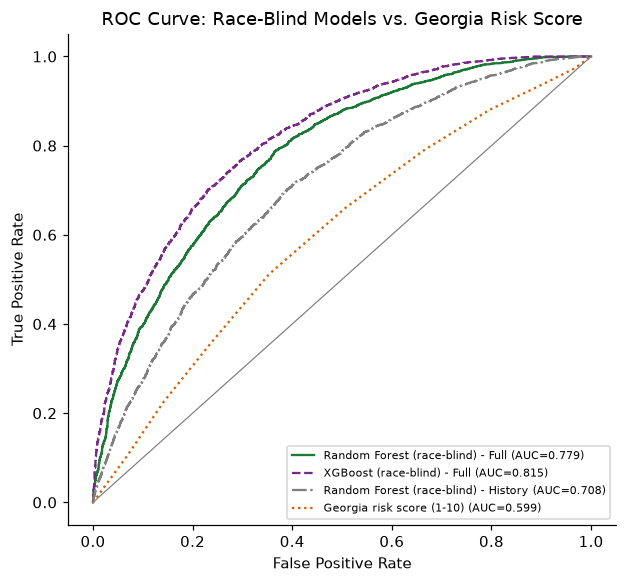

In [12]:
fig, ax = plt.subplots(figsize=(5.8, 5.4))
curves = [(f"{RF_LABEL} - {PRIMARY_SPEC}", rf_proba, "-", "#1b7837"),
          (f"{GB_LABEL} - {PRIMARY_SPEC}", gb_proba, "--", "#762a83"),
          (INC_LABEL.replace(" (>= 5)", " (1-10)"), inc_proba_test, ":", "#d55e00")]
if PRIMARY_SPEC != "History":
    curves.insert(2, (f"{RF_LABEL} - History", fitted["History"]["rf_proba"], "-.", "#7f7f7f"))
for label, p, style, color in curves:
    fpr_, tpr_, _ = roc_curve(y_test, p)
    ax.plot(fpr_, tpr_, style, color=color, label=f"{label} (AUC={roc_auc_score(y_test, p):.3f})")
ax.plot([0, 1], [0, 1], color="grey", lw=0.8)
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve: Race-Blind Models vs. Georgia Risk Score"); ax.legend(fontsize=7.5, loc="lower right")
plt.tight_layout(); savefig("fig2_roc"); plt.show()

### 5.2 Cross-validation

As in the COMPAS study, performance is re-estimated with 5-fold stratified cross-validation. Because folds share training data, the interval `mean +/- 1.96 SD/sqrt(5)` (kept for parity with the COMPAS manuscript) is **approximate and optimistic**; report it as such, or prefer the SD across folds. The incumbent score involves no fitting, so its AUC on the full analytic sample is shown as a reference line.

,Specification,Model,Mean AUC,SD,Approx. 95% CI,Fold AUCs
0,History,Random Forest,0.705834,0.006194,"[0.700, 0.711]","[0.705, 0.699, 0.704, 0.703, 0.717]"
1,History,XGBoost,0.715852,0.005119,"[0.711, 0.720]","[0.714, 0.71, 0.715, 0.715, 0.725]"
2,Full,Random Forest,0.782471,0.006633,"[0.777, 0.788]","[0.776, 0.785, 0.789, 0.773, 0.789]"
3,Full,XGBoost,0.820134,0.003652,"[0.817, 0.823]","[0.819, 0.822, 0.825, 0.815, 0.819]"


Incumbent score AUC on the full analytic sample (no fitting): 0.605


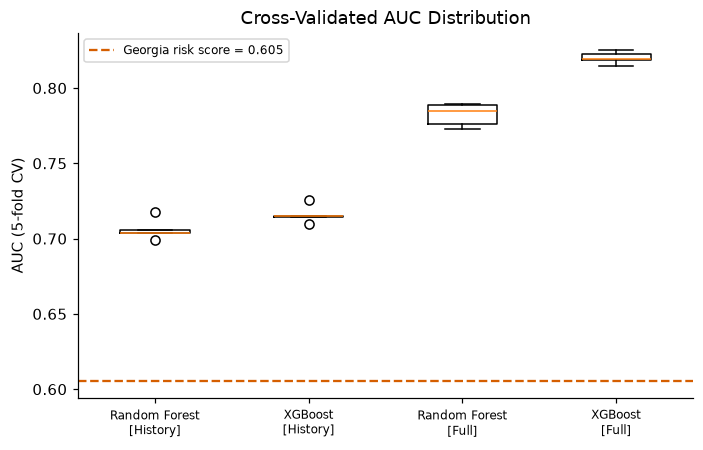

In [13]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_specs = list(dict.fromkeys(["History", PRIMARY_SPEC]))
cv_scores, cv_rows = {}, []
for spec in cv_specs:
    Xs = SPEC_FEATURES[spec]
    for label, factory in [("Random Forest", make_rf), ("XGBoost" if XGB_AVAILABLE else "HistGB", make_gb)]:
        sc = cross_val_score(factory(), Xs, y, cv=skf, scoring="roc_auc")
        cv_scores[(spec, label)] = sc
        half = 1.96 * sc.std() / np.sqrt(len(sc))
        cv_rows.append({"Specification": spec, "Model": label, "Mean AUC": sc.mean(), "SD": sc.std(),
                        "Approx. 95% CI": f"[{sc.mean()-half:.3f}, {sc.mean()+half:.3f}]",
                        "Fold AUCs": np.round(sc, 3).tolist()})
cv_table = pd.DataFrame(cv_rows)
display(cv_table)
save_table(cv_table, "table_cross_validation", index=False)
inc_auc_full = roc_auc_score(y, score / 10.0)
print(f"Incumbent score AUC on the full analytic sample (no fitting): {inc_auc_full:.3f}")

fig, ax = plt.subplots(figsize=(6.5, 4.2))
keys = list(cv_scores)
ax.boxplot([cv_scores[k] for k in keys]); ax.set_xticklabels([f"{k[1]}\n[{k[0]}]" for k in keys], fontsize=8)
ax.axhline(inc_auc_full, color="#d55e00", linestyle="--", label=f"Georgia risk score = {inc_auc_full:.3f}")
ax.set_ylabel("AUC (5-fold CV)"); ax.set_title("Cross-Validated AUC Distribution"); ax.legend(fontsize=8)
plt.tight_layout(); savefig("fig3_cv_auc"); plt.show()

## 6. Explainable AI: SHAP Analysis

As in the COMPAS study, SHAP (Lundberg & Lee, 2017) is applied to the Random Forest of the primary specification. Three questions are answered:

1. **Which inputs drive predictions?** (global importance, immediately below)
2. **Does the model treat the same input value the same way for both groups?** (dependence plots, Section 6.1; functional-form check, Section 6.2)
3. **Where does the group difference in average predicted risk come from?** Because SHAP values are additive, the gap in mean predicted risk between the two groups equals the sum of the groups' mean-SHAP differences over features, giving an exact feature-level decomposition (Section 6.3).

In [14]:
explainer = shap.TreeExplainer(rf)
shap_raw = explainer.shap_values(X_test)

def positive_class(values):
    if isinstance(values, list):   return values[1]
    if values.ndim == 3:           return values[:, :, 1]
    return values

sv = positive_class(shap_raw)
base_value = explainer.expected_value
base_value = base_value[1] if np.ndim(base_value) > 0 else base_value
additivity_error = np.abs(sv.sum(axis=1) + base_value - rf_proba).max()
print(f"SHAP matrix: {sv.shape}   |   max additivity error = {additivity_error:.2e}")
assert additivity_error < 1e-4, "SHAP values are not additive - check shap/sklearn versions"

mean_abs_shap = pd.Series(np.abs(sv).mean(axis=0), index=X_test.columns).sort_values(ascending=False)
table_shap = mean_abs_shap.to_frame("Mean |SHAP|")
save_table(table_shap, "table3_mean_abs_shap")
display(table_shap.head(15).round(4))

SHAP matrix: (7608, 49)   |   max additivity error = 1.88e-14


,Mean |SHAP|
Percent_Days_Employed,0.0668
Gang_Affiliated,0.0304
_v1,0.0296
Age_at_Release,0.0250
Jobs_Per_Year,0.0180
Prior_Arrest_Episodes_Felony,0.0167
Prior_Arrest_Episodes_Misd,0.0120
Prior_Arrest_Episodes_Property,0.0112
DrugTests_THC_Positive,0.0105
Prior_Conviction_Episodes_Misd,0.0096


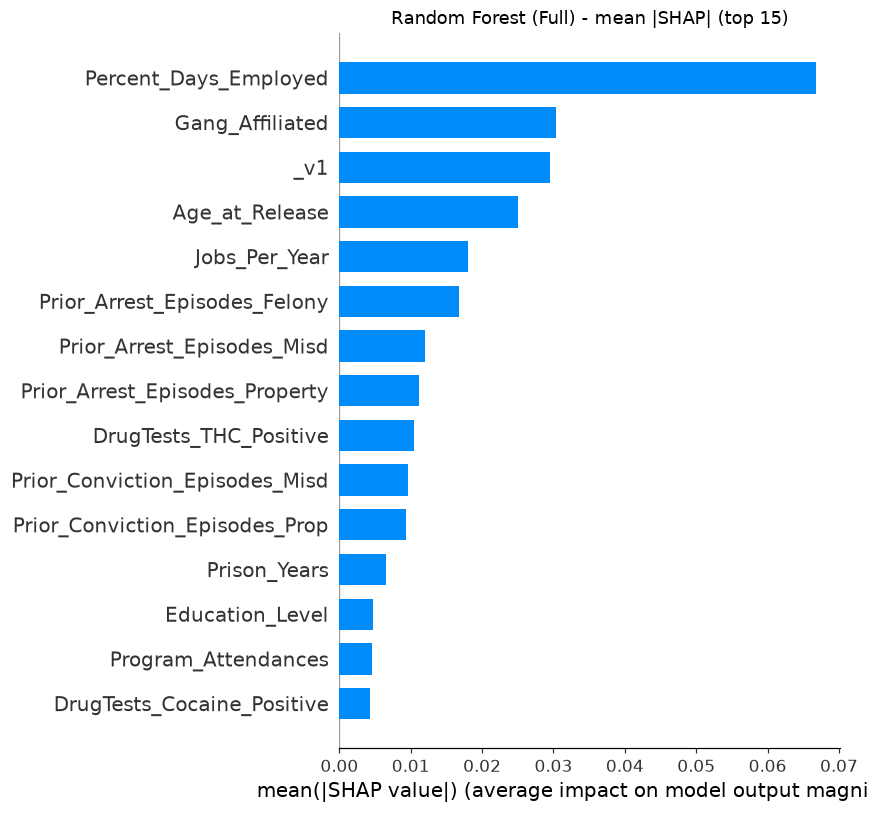

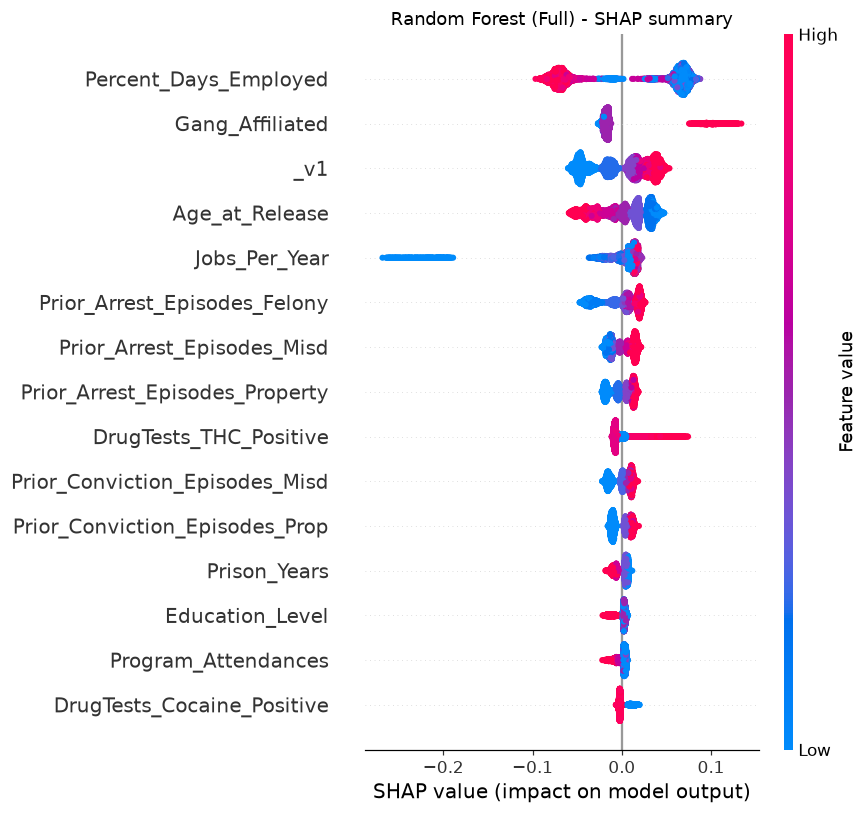

In [15]:
plt.figure(figsize=(7, 5.2))
shap.summary_plot(sv, X_test, plot_type="bar", max_display=15, show=False)
plt.title(f"Random Forest ({PRIMARY_SPEC}) - mean |SHAP| (top 15)")
plt.tight_layout(); savefig("fig4a_shap_bar"); plt.show()

plt.figure(figsize=(7.5, 6))
shap.summary_plot(sv, X_test, max_display=15, show=False)
plt.title(f"Random Forest ({PRIMARY_SPEC}) - SHAP summary")
plt.tight_layout(); savefig("fig4b_shap_summary"); plt.show()

### 6.1 Dependence plots by race

Race is used here **for coloring only**; it is not a model input. If the colored point clouds trace the same curve, the model is applying one functional relationship to everyone.

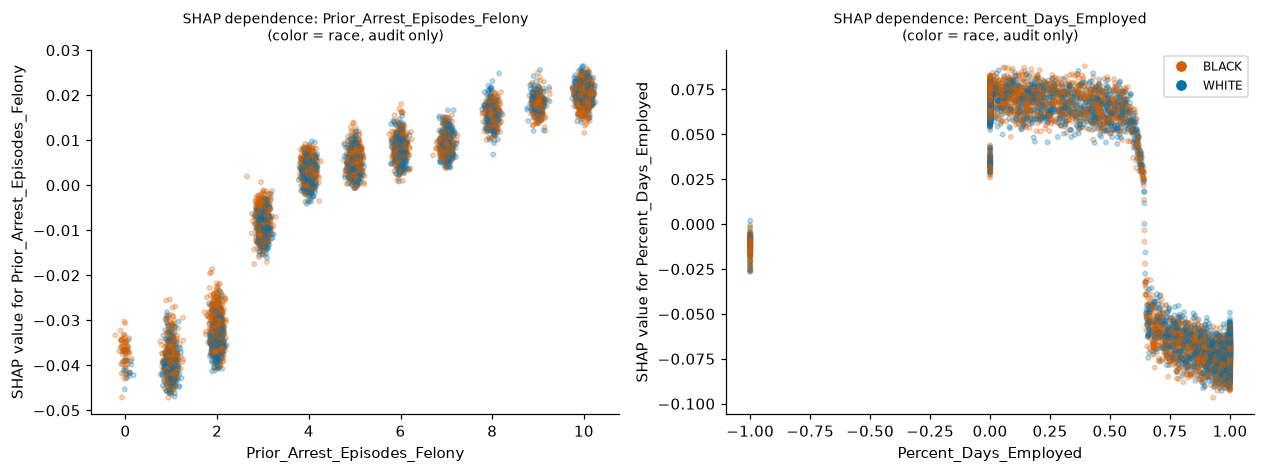

In [16]:
dep_features = [f for f in ["Prior_Arrest_Episodes_Felony", "Percent_Days_Employed"] if f in X_test.columns]
fig, axes = plt.subplots(1, len(dep_features), figsize=(5.8 * len(dep_features), 4.4), squeeze=False)
rng_j = np.random.default_rng(SEED)
for ax, feat in zip(axes[0], dep_features):
    j = list(X_test.columns).index(feat)
    xv = X_test[feat].to_numpy(dtype=float)
    jitter = rng_j.normal(0, 0.08, len(xv)) if len(np.unique(xv)) <= 12 else 0
    ax.scatter(xv + jitter, sv[:, j], c=[COLORS[r] for r in race_test], alpha=0.25, s=9)
    ax.set_xlabel(feat); ax.set_ylabel(f"SHAP value for {feat}")
    ax.set_title(f"SHAP dependence: {feat}\n(color = race, audit only)", fontsize=9)
ax.legend(handles=[plt.Line2D([0], [0], marker="o", ls="", color=COLORS[G1], label=G1),
                   plt.Line2D([0], [0], marker="o", ls="", color=COLORS[G2], label=G2)], fontsize=8)
plt.tight_layout(); savefig("fig5_shap_dependence"); plt.show()

### 6.2 Functional-form check: mean SHAP value by feature value and race

For a feature, the table gives the mean SHAP contribution within each value (or quantile bin) for each group. Small differences between the two columns mean the model scores identical inputs identically, whatever the group.

In [17]:
def shap_curve_by_race(feature, n_bins=8):
    j = list(X_test.columns).index(feature)
    x = X_test[feature].to_numpy(dtype=float)
    grouping = x if len(np.unique(x)) <= 12 else pd.qcut(x, n_bins, duplicates="drop")
    t = pd.DataFrame({"bin": grouping, "shap": sv[:, j], "race": race_test})
    out = t.groupby(["bin", "race"], observed=True)["shap"].agg(["mean", "count"]).unstack("race")
    res = pd.DataFrame({f"mean SHAP {G1}": out[("mean", G1)], f"mean SHAP {G2}": out[("mean", G2)],
                        f"n {G1}": out[("count", G1)], f"n {G2}": out[("count", G2)]})
    res["difference"] = res[f"mean SHAP {G1}"] - res[f"mean SHAP {G2}"]
    return res.dropna()

functional_form = {}
for feat in dep_features:
    tab = shap_curve_by_race(feat)
    ok = tab[(tab[f"n {G1}"] >= 30) & (tab[f"n {G2}"] >= 30)]
    functional_form[feat] = {"max |difference| (cells with n>=30 in both groups)": ok["difference"].abs().max(),
                             "correlation of the two curves": ok[f"mean SHAP {G1}"].corr(ok[f"mean SHAP {G2}"]),
                             "range of the BLACK curve": ok[f"mean SHAP {G1}"].max() - ok[f"mean SHAP {G1}"].min()}
    print(f"--- {feat} ---"); display(tab.round(4))
    save_table(tab, f"table_shap_curve_{feat}")
ff_summary = pd.DataFrame(functional_form).T
display(ff_summary.round(4))

--- Prior_Arrest_Episodes_Felony ---


,mean SHAP BLACK,mean SHAP WHITE,n BLACK,n WHITE,difference
bin,,,,,
0.0,-0.0371,-0.0399,59,19,0.0028
1.0,-0.0386,-0.0396,406,273,0.0010
2.0,-0.0315,-0.0336,454,319,0.0021
3.0,-0.0078,-0.0087,516,322,0.0009
4.0,0.0035,0.0028,441,317,0.0007
5.0,0.0056,0.0050,424,309,0.0006
6.0,0.0082,0.0079,346,312,0.0003
7.0,0.0091,0.0092,274,250,-0.0001
8.0,0.0159,0.0158,247,214,0.0001


--- Percent_Days_Employed ---


,mean SHAP BLACK,mean SHAP WHITE,n BLACK,n WHITE,difference
bin,,,,,
"(-1.001, 0.0]",0.0627,0.0617,1604,840,0.0010
"(0.0, 0.135]",0.0716,0.0698,264,145,0.0018
"(0.135, 0.471]",0.0682,0.0669,551,400,0.0013
"(0.471, 0.787]",-0.0049,-0.0006,538,413,-0.0043
"(0.787, 0.968]",-0.0717,-0.0713,489,462,-0.0004
"(0.968, 1.0]",-0.0720,-0.0712,939,963,-0.0008


,max |difference| (cells with n>=30 in both groups),correlation of the two curves,range of the BLACK curve
Prior_Arrest_Episodes_Felony,0.0021,0.9998,0.0587
Percent_Days_Employed,0.0043,0.9996,0.1437


### 6.3 SHAP decomposition of the group gap in mean predicted risk

Mean predicted risk gap = (mean predicted risk of BLACK) - (mean predicted risk of WHITE) = sum over features of [mean SHAP<sub>BLACK</sub> - mean SHAP<sub>WHITE</sub>]. The decomposition below is exact. A feature contributes to the gap only if the groups differ on it **and** the model uses it, which is the formal sense in which a seemingly neutral input acts as a proxy.

Mean predicted risk: BLACK = 0.524,  WHITE = 0.500,  gap = +0.023


,Mean SHAP BLACK,Mean SHAP WHITE,Contribution to gap,Input SMD (BLACK-WHITE),Mean |SHAP|,Share of gap (%)
Percent_Days_Employed,0.0118,-0.0040,0.0158,-0.2399,0.0668,68.4093
Gang_Affiliated,0.0047,-0.0054,0.0101,0.3785,0.0304,43.6821
Age_at_Release,0.0044,-0.0024,0.0068,-0.2492,0.0250,29.3213
DrugTests_THC_Positive,0.0029,-0.0023,0.0052,0.0964,0.0105,22.4497
_v1,-0.0003,0.0031,-0.0035,-0.1209,0.0296,-14.9413
Prior_Arrest_Episodes_Property,-0.0006,0.0022,-0.0028,-0.1830,0.0112,-11.8918
Prior_Conviction_Episodes_Prop,-0.0005,0.0016,-0.0021,-0.1765,0.0093,-9.0832
Gender_M,0.0010,-0.0011,0.0021,0.3532,0.0037,8.9986
DrugTests_Meth_Positive,-0.0005,0.0013,-0.0019,-0.0448,0.0037,-8.1192
Jobs_Per_Year,-0.0007,0.0011,-0.0018,-0.2134,0.0180,-7.6584


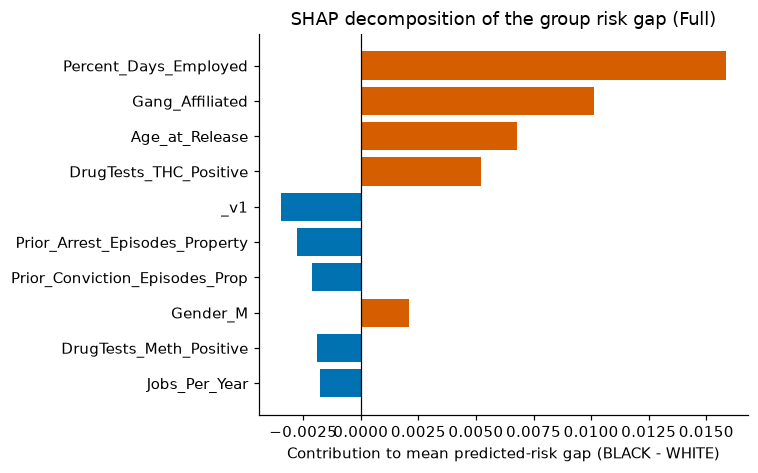

In [18]:
m_b = race_test == G1
gap_contrib = sv[m_b].mean(axis=0) - sv[~m_b].mean(axis=0)
decomp = pd.DataFrame({"Mean SHAP BLACK": sv[m_b].mean(axis=0), "Mean SHAP WHITE": sv[~m_b].mean(axis=0),
                       "Contribution to gap": gap_contrib,
                       "Input SMD (BLACK-WHITE)": [gap.loc[c, "SMD (BLACK - WHITE)"] for c in X_test.columns],
                       "Mean |SHAP|": mean_abs_shap.reindex(X_test.columns).values}, index=X_test.columns)
total_gap = rf_proba[m_b].mean() - rf_proba[~m_b].mean()
assert abs(decomp["Contribution to gap"].sum() - total_gap) < 1e-6, "Decomposition does not add up"
decomp["Share of gap (%)"] = 100 * decomp["Contribution to gap"] / total_gap if abs(total_gap) > 1e-9 else np.nan
decomp = decomp.reindex(decomp["Contribution to gap"].abs().sort_values(ascending=False).index)
print(f"Mean predicted risk: {G1} = {rf_proba[m_b].mean():.3f},  {G2} = {rf_proba[~m_b].mean():.3f},  gap = {total_gap:+.3f}")
display(decomp.head(10).round(4))
save_table(decomp, "table4_shap_gap_decomposition")

top = decomp.head(10)
fig, ax = plt.subplots(figsize=(7, 4.4))
ax.barh(top.index[::-1], top["Contribution to gap"][::-1], color=["#d55e00" if v > 0 else "#0072b2" for v in top["Contribution to gap"][::-1]])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel(f"Contribution to mean predicted-risk gap ({G1} - {G2})")
ax.set_title(f"SHAP decomposition of the group risk gap ({PRIMARY_SPEC})")
plt.tight_layout(); savefig("fig6_shap_gap_decomposition"); plt.show()

## 7. Fairness Audit: Error-Rate Disparities by Race

Following Angwin et al. (2016) and the COMPAS study, we compare the **False Positive Rate** (labelled high-risk but not re-arrested within 3 years) and the **False Negative Rate** (labelled low-risk but re-arrested) for the race-blind models and the incumbent Georgia score (>= 5). Ratios are BLACK / WHITE. All three classifiers are evaluated on the **same test rows**.

Two additions relative to the COMPAS manuscript: (i) **bootstrap 95% confidence intervals** (group-stratified, 1,000 replicates), because ratios close to 1 cannot be interpreted without a measure of uncertainty, and (ii) absolute **differences** next to ratios, because a ratio can look large when both rates are small.

In [19]:
audit_models = {RF_LABEL:  (rf_pred, rf_proba),
                GB_LABEL:  (gb_pred, gb_proba),
                INC_LABEL: (inc_pred_test, inc_proba_test)}

table3 = pd.concat([group_table(n, y_test, pr, race_test, [G1, G2], proba=pp) for n, (pr, pp) in audit_models.items()],
                   ignore_index=True)
print("Table 5. FPR, FNR and PPV by race (test set):")
display(table3.round(3))
save_table(table3, "table5_fairness_by_group", index=False)

disp_rows = []
for n, (pr, pp) in audit_models.items():
    bd = bootstrap_disparity(y_test, pr, race_test, G1, G2)
    for metric, r in bd.iterrows():
        null = 1.0 if "ratio" in metric else 0.0
        disp_rows.append({"Model": n, "Metric": metric, "Estimate": r["estimate"], "CI low": r["ci_low"], "CI high": r["ci_high"],
                          "CI excludes parity": not (r["ci_low"] <= null <= r["ci_high"])})
disparity = pd.DataFrame(disp_rows)
print("\nTable 6. Disparity metrics with group-stratified bootstrap 95% CIs (parity: ratio = 1, difference = 0):")
display(disparity.round(3))
save_table(disparity, "table6_disparity_bootstrap", index=False)

Table 5. FPR, FNR and PPV by race (test set):


,Model,Group,N,Base rate,Flag rate,FPR,FNR,PPV,AUC (within group)
0,Random Forest (race-blind),BLACK,4385,0.582,0.600,0.372,0.235,0.741,0.766
1,Random Forest (race-blind),WHITE,3223,0.567,0.527,0.277,0.282,0.773,0.799
2,XGBoost (race-blind),BLACK,4385,0.582,0.676,0.433,0.149,0.732,0.802
3,XGBoost (race-blind),WHITE,3223,0.567,0.604,0.325,0.183,0.767,0.835
4,Georgia risk score (>= 5),BLACK,4385,0.582,0.751,0.681,0.198,0.621,0.598
5,Georgia risk score (>= 5),WHITE,3223,0.567,0.718,0.644,0.226,0.611,0.600



Table 6. Disparity metrics with group-stratified bootstrap 95% CIs (parity: ratio = 1, difference = 0):


,Model,Metric,Estimate,CI low,CI high,CI excludes parity
0,Random Forest (race-blind),FPR ratio,1.343,1.213,1.518,True
1,Random Forest (race-blind),FNR ratio,0.835,0.758,0.929,True
2,Random Forest (race-blind),FPR diff,0.095,0.064,0.131,True
3,Random Forest (race-blind),FNR diff,-0.047,-0.072,-0.018,True
4,XGBoost (race-blind),FPR ratio,1.329,1.213,1.466,True
5,XGBoost (race-blind),FNR ratio,0.815,0.712,0.929,True
6,XGBoost (race-blind),FPR diff,0.107,0.073,0.143,True
7,XGBoost (race-blind),FNR diff,-0.034,-0.056,-0.012,True
8,Georgia risk score (>= 5),FPR ratio,1.056,1.009,1.111,True
9,Georgia risk score (>= 5),FNR ratio,0.878,0.782,0.984,True


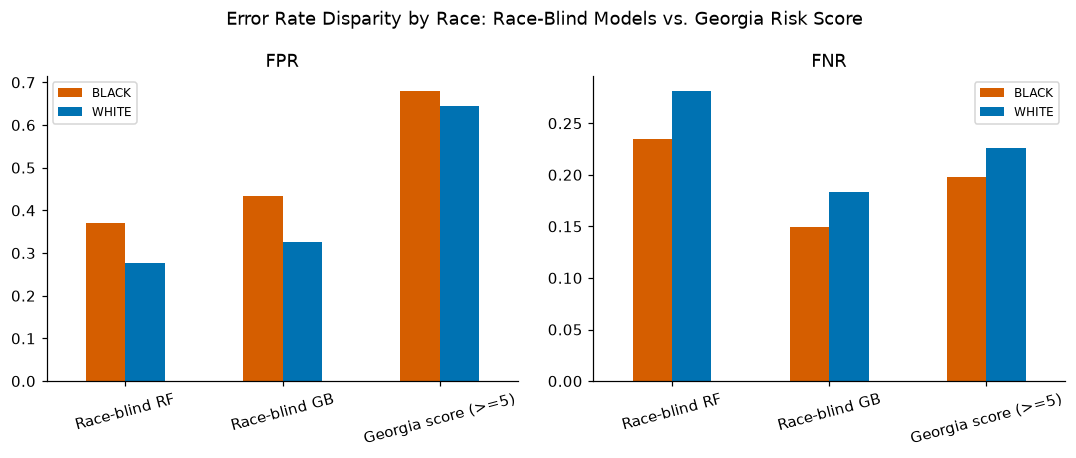

Race-blind RF          FPR ratio = 1.34x [1.21, 1.52]   FNR ratio = 0.83x [0.76, 0.93]
Race-blind GB          FPR ratio = 1.33x [1.21, 1.47]   FNR ratio = 0.81x [0.71, 0.93]
Georgia score (>=5)    FPR ratio = 1.06x [1.01, 1.11]   FNR ratio = 0.88x [0.78, 0.98]


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
short = {RF_LABEL: "Race-blind RF", GB_LABEL: "Race-blind GB", INC_LABEL: "Georgia score (>=5)"}
for ax, metric in zip(axes, ["FPR", "FNR"]):
    piv = table3.pivot(index="Model", columns="Group", values=metric).loc[list(audit_models)][[G1, G2]]
    piv.index = [short[i] for i in piv.index]
    piv.plot(kind="bar", ax=ax, color=[COLORS[G1], COLORS[G2]])
    ax.set_title(metric); ax.tick_params(axis="x", rotation=15); ax.legend(fontsize=8)
plt.suptitle("Error Rate Disparity by Race: Race-Blind Models vs. Georgia Risk Score")
plt.tight_layout(); savefig("fig7_error_rates_by_race"); plt.show()

for n in audit_models:
    s = disparity[disparity["Model"] == n].set_index("Metric")
    print(f"{short[n]:22s} FPR ratio = {s.loc['FPR ratio','Estimate']:.2f}x [{s.loc['FPR ratio','CI low']:.2f}, {s.loc['FPR ratio','CI high']:.2f}]"
          f"   FNR ratio = {s.loc['FNR ratio','Estimate']:.2f}x [{s.loc['FNR ratio','CI low']:.2f}, {s.loc['FNR ratio','CI high']:.2f}]")

### 7.1 Does removing race change anything? Specification diagnostics

Each specification is a Random Forest at the default threshold, audited on the same test rows. Comparing **Full** with **Full+Race (diagnostic)** answers directly whether *giving* the model race changes its error-rate pattern; comparing **Full** with **Full+PUMA** probes a geographic proxy; comparing **History** with **Full** shows how the disparity depends on which information the model sees.

In [21]:
spec_rows = []
for name, d in fitted.items():
    pr = (d["rf_proba"] >= THRESHOLD).astype(int)
    g = group_table(name, y_test, pr, race_test, [G1, G2]).set_index("Group")
    bd = bootstrap_disparity(y_test, pr, race_test, G1, G2)
    fmt = lambda m: f"{bd.loc[m,'estimate']:.2f} [{bd.loc[m,'ci_low']:.2f}, {bd.loc[m,'ci_high']:.2f}]"
    spec_rows.append({"Specification": name, "AUC": roc_auc_score(y_test, d["rf_proba"]),
                      f"FPR {G1}": g.loc[G1, "FPR"], f"FPR {G2}": g.loc[G2, "FPR"], "FPR ratio [95% CI]": fmt("FPR ratio"),
                      f"FNR {G1}": g.loc[G1, "FNR"], f"FNR {G2}": g.loc[G2, "FNR"], "FNR ratio [95% CI]": fmt("FNR ratio"),
                      "Mean predicted risk gap": d["rf_proba"][race_test == G1].mean() - d["rf_proba"][race_test == G2].mean()})
spec_audit = pd.DataFrame(spec_rows).set_index("Specification")
display(spec_audit.round(3))
save_table(spec_audit, "table7_specification_audit")

,AUC,FPR BLACK,FPR WHITE,FPR ratio [95% CI],FNR BLACK,FNR WHITE,FNR ratio [95% CI],Mean predicted risk gap
Specification,,,,,,,,
History,0.708,0.439,0.407,"1.08 [1.00, 1.18]",0.281,0.260,"1.08 [0.97, 1.19]",0.006
Full,0.779,0.372,0.277,"1.34 [1.21, 1.52]",0.235,0.282,"0.83 [0.76, 0.93]",0.023
Full+PUMA,0.778,0.372,0.280,"1.33 [1.21, 1.49]",0.234,0.273,"0.86 [0.77, 0.95]",0.021
Full+Race (diagnostic),0.779,0.362,0.271,"1.33 [1.21, 1.51]",0.243,0.283,"0.86 [0.78, 0.95]",0.025


### 7.2 Why the disparity is large or small: the Chouldechova decomposition

For each group, FPR = [p / (1 - p)] x [(1 - PPV) / PPV] x TPR, where p is the group's base rate. Taking ratios across groups gives an **exact** decomposition:

FPR ratio = (base-rate odds ratio) x (PPV-odds ratio) x (TPR ratio).

If predictive parity holds (PPV equal across groups) and TPRs are similar, the FPR ratio is driven by the base-rate odds ratio alone. This is the arithmetic behind the calibration / error-rate impossibility result, and it is the key to comparing datasets with very different base-rate gaps (Section 11).

In [22]:
chould = pd.DataFrame({short[n]: chouldechova_terms(y_test, pr, race_test, G1, G2) for n, (pr, pp) in audit_models.items()}).T
display(chould.round(3))
assert np.allclose(chould["Product (= FPR ratio)"], chould["FPR ratio (observed)"]), "Identity check failed"
save_table(chould, "table8_chouldechova_decomposition")

,Base-rate odds ratio,PPV-odds ratio,TPR ratio,Product (= FPR ratio),FPR ratio (observed)
Race-blind RF,1.062,1.187,1.065,1.343,1.343
Race-blind GB,1.062,1.201,1.042,1.329,1.329
Georgia score (>=5),1.062,0.960,1.036,1.056,1.056


## 8. Model Calibration

Calibration asks whether a given predicted probability means the same thing for everyone. As discussed by Chouldechova (2017) and Kleinberg et al. (2016), calibration parity and equal error rates cannot generally both hold when base rates differ across groups. Quantile bins are used throughout: 10 bins overall and **6 bins per group** (the same choices as in the COMPAS manuscript, to keep the "mean absolute calibration gap" comparable).

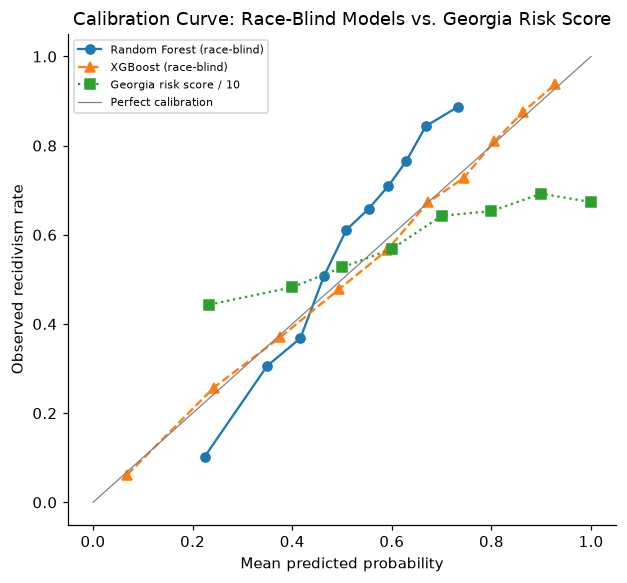

In [23]:
fig, ax = plt.subplots(figsize=(5.8, 5.4))
for name, proba, marker in [(f"{RF_LABEL}", rf_proba, "o-"), (f"{GB_LABEL}", gb_proba, "^--"),
                            ("Georgia risk score / 10", inc_proba_test, "s:")]:
    fp_, mp_ = calibration_curve(y_test, proba, n_bins=10, strategy="quantile")
    ax.plot(mp_, fp_, marker, label=name)
ax.plot([0, 1], [0, 1], color="grey", lw=0.8, label="Perfect calibration")
ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed recidivism rate")
ax.set_title("Calibration Curve: Race-Blind Models vs. Georgia Risk Score"); ax.legend(fontsize=7.5)
plt.tight_layout(); savefig("fig8_calibration_overall"); plt.show()

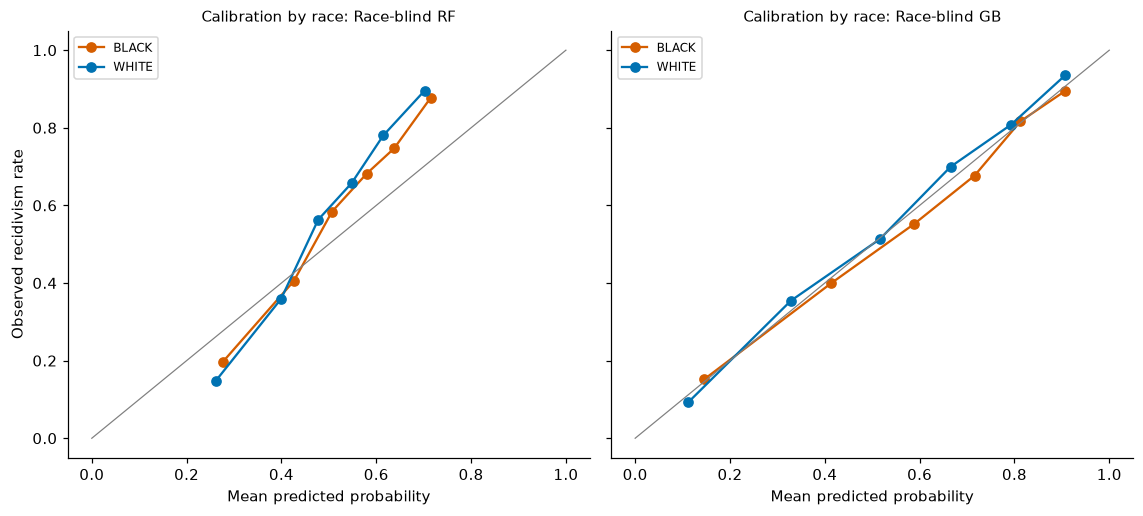

,Model,Group,Mean |calibration gap| (6 bins),Brier score
0,Random Forest (race-blind),BLACK,0.092,0.201
1,Random Forest (race-blind),WHITE,0.118,0.196
2,XGBoost (race-blind),BLACK,0.019,0.177
3,XGBoost (race-blind),WHITE,0.021,0.163


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.8), sharey=True)
cal_rows = []
for ax, (name, proba) in zip(axes, [(RF_LABEL, rf_proba), (GB_LABEL, gb_proba)]):
    for g in [G1, G2]:
        m = race_test == g
        gap_g, fr, mp = calibration_gap(y_test.to_numpy()[m], proba[m], n_bins=6)
        ax.plot(mp, fr, "o-", color=COLORS[g], label=g)
        cal_rows.append({"Model": name, "Group": g, "Mean |calibration gap| (6 bins)": gap_g,
                         "Brier score": brier_score_loss(y_test.to_numpy()[m], proba[m])})
    ax.plot([0, 1], [0, 1], color="grey", lw=0.8)
    ax.set_title(f"Calibration by race: {short[name]}", fontsize=10); ax.set_xlabel("Mean predicted probability"); ax.legend(fontsize=8)
axes[0].set_ylabel("Observed recidivism rate")
plt.tight_layout(); savefig("fig9_calibration_by_race"); plt.show()

cal_table = pd.DataFrame(cal_rows)
display(cal_table.round(3))
save_table(cal_table, "table9_calibration_by_race", index=False)
cal_gap_rf = cal_table[cal_table["Model"] == RF_LABEL].set_index("Group")["Mean |calibration gap| (6 bins)"]

### 8.1 Predictive parity of the incumbent score

The vendor-side defence of COMPAS (Dieterich et al., 2016) rested on *predictive parity*: at each score level, the observed re-offending rate is about the same for both groups. The same check for the Georgia score is shown below (cells with fewer than 30 people per group are flagged and not plotted).

,Observed rate BLACK,Observed rate WHITE,n BLACK,n WHITE,Difference,Both n >= 30
score,,,,,,
1,0.534,0.494,146,83,0.040,True
2,0.458,0.405,166,158,0.053,True
3,0.430,0.412,316,306,0.019,True
4,0.467,0.503,463,362,-0.036,True
5,0.525,0.529,613,473,-0.003,True
6,0.579,0.552,691,451,0.027,True
7,0.641,0.646,651,418,-0.005,True
8,0.656,0.650,511,363,0.005,True
9,0.685,0.702,448,309,-0.017,True


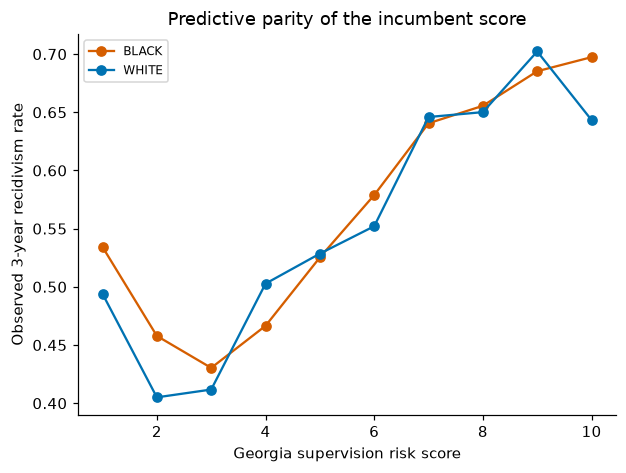

Mean absolute BLACK-WHITE difference in observed rate across score levels: 0.026


In [25]:
inc_df = pd.DataFrame({"score": score_test, "y": y_test.to_numpy(), "race": race_test})
inc_tab = inc_df.groupby(["score", "race"])["y"].agg(["mean", "count"]).unstack("race")
inc_out = pd.DataFrame({f"Observed rate {G1}": inc_tab[("mean", G1)], f"Observed rate {G2}": inc_tab[("mean", G2)],
                        f"n {G1}": inc_tab[("count", G1)], f"n {G2}": inc_tab[("count", G2)]})
inc_out["Difference"] = inc_out[f"Observed rate {G1}"] - inc_out[f"Observed rate {G2}"]
inc_out["Both n >= 30"] = (inc_out[f"n {G1}"] >= 30) & (inc_out[f"n {G2}"] >= 30)
inc_out.index = inc_out.index.astype(int)
display(inc_out.round(3))
save_table(inc_out, "table10_incumbent_predictive_parity")

ok = inc_out[inc_out["Both n >= 30"]]
fig, ax = plt.subplots(figsize=(5.8, 4.4))
for g in [G1, G2]:
    ax.plot(ok.index, ok[f"Observed rate {g}"], "o-", color=COLORS[g], label=g)
ax.set_xlabel("Georgia supervision risk score"); ax.set_ylabel("Observed 3-year recidivism rate")
ax.set_title("Predictive parity of the incumbent score"); ax.legend(fontsize=8)
plt.tight_layout(); savefig("fig10_incumbent_predictive_parity"); plt.show()
print(f"Mean absolute BLACK-WHITE difference in observed rate across score levels: {ok['Difference'].abs().mean():.3f}")

## 9. Classification-Threshold Sensitivity

The 0.5 threshold is a default, not a requirement. Section 9.1 sweeps the model threshold from 0.20 to 0.80 in 0.05 steps (13 points, as in the COMPAS manuscript). Ratios computed from very few false positives are unreliable, so points where either group has fewer than 30 false positives are marked **unstable** and drawn with hollow markers.

,Threshold,Accuracy,F1,FPR (BLACK),FPR (WHITE),FPR ratio,FPR diff,FNR (BLACK),FNR (WHITE),FNR ratio,Stable
0,0.20,0.604,0.744,0.933,0.928,1.006,0.005,0.001,0.001,2.149,True
1,0.25,0.626,0.754,0.880,0.862,1.021,0.018,0.008,0.003,2.507,True
2,0.30,0.655,0.766,0.806,0.765,1.054,0.041,0.018,0.016,1.122,True
3,0.35,0.676,0.773,0.739,0.667,1.109,0.073,0.039,0.045,0.854,True
4,0.40,0.700,0.779,0.632,0.545,1.160,0.087,0.076,0.092,0.827,True
5,0.45,0.723,0.779,0.481,0.408,1.178,0.073,0.144,0.160,0.900,True
6,0.50,0.713,0.750,0.372,0.277,1.343,0.095,0.235,0.282,0.835,True
7,0.55,0.686,0.697,0.271,0.182,1.489,0.089,0.347,0.411,0.844,True
8,0.60,0.639,0.602,0.167,0.098,1.705,0.069,0.499,0.562,0.888,True
9,0.65,0.567,0.434,0.071,0.039,1.846,0.033,0.688,0.743,0.926,True


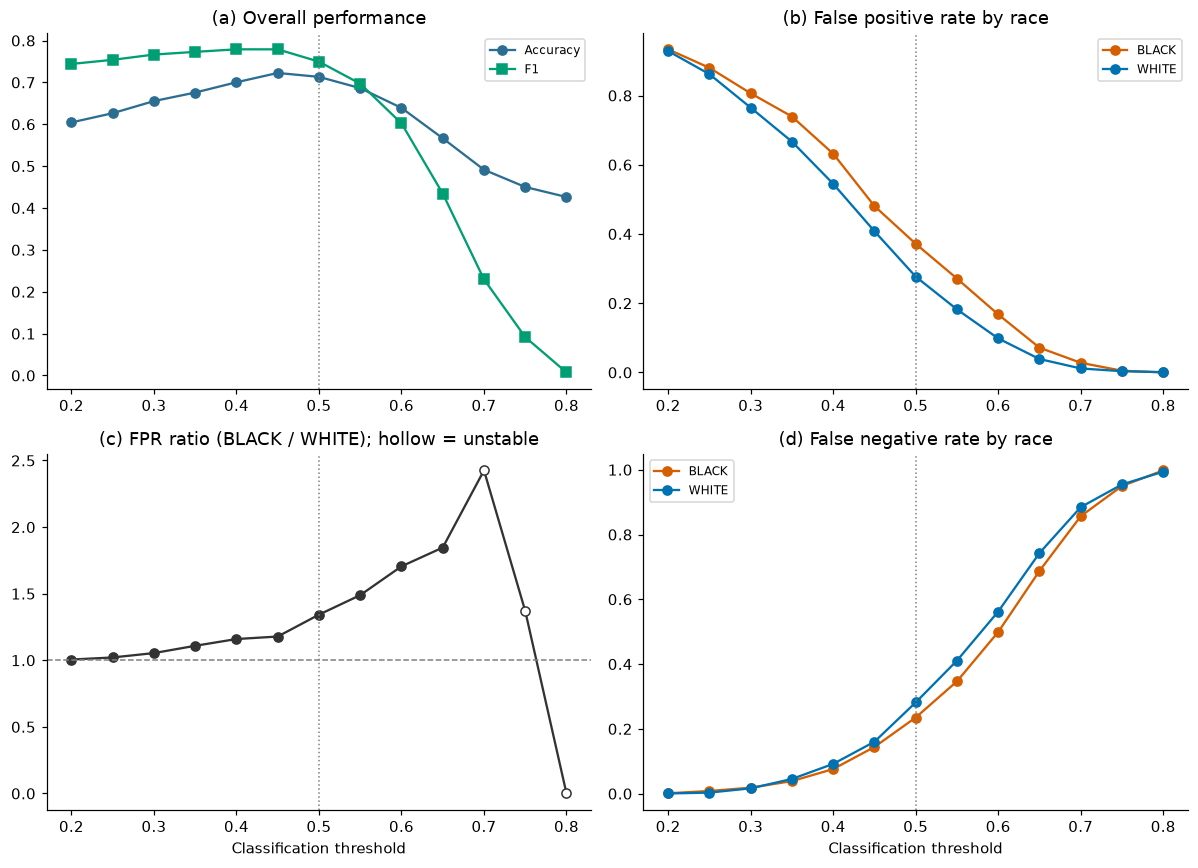

FPR ratio across stable thresholds: 1.01x to 1.85x (peak at threshold 0.65);  unstable points: [0.7, 0.75, 0.8]


In [26]:
thresholds = np.arange(0.20, 0.801, 0.05)
sweep = threshold_sweep(y_test, rf_proba, race_test, G1, G2, thresholds)
display(sweep.drop(columns=["min FP count"]).round(3))
save_table(sweep, "table11_threshold_sweep", index=False)

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
ax = axes[0, 0]
ax.plot(sweep["Threshold"], sweep["Accuracy"], "o-", label="Accuracy", color="#2c6e91")
ax.plot(sweep["Threshold"], sweep["F1"], "s-", label="F1", color="#009e73")
ax.axvline(THRESHOLD, color="grey", ls=":", lw=1); ax.set_title("(a) Overall performance"); ax.legend(fontsize=8)
ax = axes[0, 1]
for g in [G1, G2]:
    ax.plot(sweep["Threshold"], sweep[f"FPR ({g})"], "o-", color=COLORS[g], label=g)
ax.axvline(THRESHOLD, color="grey", ls=":", lw=1); ax.set_title("(b) False positive rate by race"); ax.legend(fontsize=8)
ax = axes[1, 0]
ax.plot(sweep["Threshold"], sweep["FPR ratio"], "-", color="#333333")
st = sweep["Stable"]
ax.plot(sweep.loc[st, "Threshold"], sweep.loc[st, "FPR ratio"], "o", color="#333333")
ax.plot(sweep.loc[~st, "Threshold"], sweep.loc[~st, "FPR ratio"], "o", mfc="white", color="#333333")
ax.axhline(1.0, color="grey", ls="--", lw=1); ax.axvline(THRESHOLD, color="grey", ls=":", lw=1)
ax.set_title("(c) FPR ratio (BLACK / WHITE); hollow = unstable"); ax.set_xlabel("Classification threshold")
ax = axes[1, 1]
for g in [G1, G2]:
    ax.plot(sweep["Threshold"], sweep[f"FNR ({g})"], "o-", color=COLORS[g], label=g)
ax.axvline(THRESHOLD, color="grey", ls=":", lw=1); ax.set_title("(d) False negative rate by race"); ax.set_xlabel("Classification threshold"); ax.legend(fontsize=8)
plt.tight_layout(); savefig("fig11_threshold_sweep"); plt.show()

stable_ratios = sweep.loc[sweep["Stable"], "FPR ratio"]
print(f"FPR ratio across stable thresholds: {stable_ratios.min():.2f}x to {stable_ratios.max():.2f}x "
      f"(peak at threshold {sweep.loc[stable_ratios.idxmax(), 'Threshold']:.2f});  "
      f"unstable points: {sweep.loc[~sweep['Stable'], 'Threshold'].tolist()}")

### 9.1 The incumbent's own cut-offs, and a matched-flag-rate comparison

The incumbent's cut-off (>= 5) is a policy choice just as the model threshold is. For every possible cut-off k, the table reports the incumbent's error rates and, for comparison, those of the Random Forest **at the threshold that flags exactly the same share of people**. Holding the flag rate fixed removes the objection that the model and the incumbent differ simply because one flags more people than the other.

In [27]:
rows = []
for k in range(2, 10):
    pred_i = (score_test >= k).astype(int)
    flag = pred_i.mean()
    tau = np.quantile(rf_proba, 1 - flag)
    pred_m = (rf_proba >= tau).astype(int)
    ri = {g: confusion_rates(y_test.to_numpy()[race_test == g], pred_i[race_test == g]) for g in (G1, G2)}
    rm = {g: confusion_rates(y_test.to_numpy()[race_test == g], pred_m[race_test == g]) for g in (G1, G2)}
    rows.append({"Cut-off k": k, "Overall flag rate": flag,
                 f"Incumbent FPR {G1}": ri[G1]["FPR"], f"Incumbent FPR {G2}": ri[G2]["FPR"],
                 "Incumbent FPR ratio": ri[G1]["FPR"] / ri[G2]["FPR"] if ri[G2]["FPR"] > 0 else np.nan,
                 "Matched RF threshold": tau,
                 f"RF FPR {G1}": rm[G1]["FPR"], f"RF FPR {G2}": rm[G2]["FPR"],
                 "RF FPR ratio": rm[G1]["FPR"] / rm[G2]["FPR"] if rm[G2]["FPR"] > 0 else np.nan,
                 "Incumbent accuracy": accuracy_score(y_test, pred_i), "RF accuracy": accuracy_score(y_test, pred_m)})
inc_sweep = pd.DataFrame(rows).set_index("Cut-off k")
display(inc_sweep.round(3))
save_table(inc_sweep, "table12_incumbent_cutoffs_matched_rf")

,Overall flag rate,Incumbent FPR BLACK,Incumbent FPR WHITE,Incumbent FPR ratio,Matched RF threshold,RF FPR BLACK,RF FPR WHITE,RF FPR ratio,Incumbent accuracy,RF accuracy
Cut-off k,,,,,,,,,,
2,0.970,0.963,0.970,0.993,0.201,0.932,0.928,1.004,0.575,0.605
3,0.927,0.914,0.903,1.013,0.269,0.852,0.834,1.021,0.580,0.636
4,0.846,0.816,0.773,1.054,0.357,0.730,0.657,1.112,0.593,0.677
5,0.737,0.681,0.644,1.056,0.424,0.568,0.480,1.182,0.597,0.712
6,0.594,0.522,0.485,1.077,0.488,0.396,0.304,1.301,0.589,0.717
7,0.444,0.363,0.340,1.069,0.557,0.261,0.170,1.535,0.569,0.681
8,0.304,0.236,0.234,1.009,0.610,0.149,0.083,1.798,0.529,0.626
9,0.189,0.140,0.143,0.979,0.651,0.070,0.039,1.818,0.494,0.565


## 10. Robustness Checks

Two checks that the results are not artifacts of one particular split:

1. **Official NIJ split.** The file ships with a `Training_Sample` flag (the split used in the NIJ challenge). Models are trained on `Training_Sample == 1` and audited on the remainder.
2. **Repeated random splits.** The primary specification is re-estimated on 10 different stratified 70/30 splits (seeds 0-9), which shows how much the AUC and the disparity ratios move from split to split.

In [28]:
official_train = (df["Training_Sample"] == 1).to_numpy()
rob_rows = []
for spec in dict.fromkeys(["History", PRIMARY_SPEC]):
    Xs = SPEC_FEATURES[spec]
    m = make_rf().fit(Xs.loc[official_train], y.loc[official_train])
    p = m.predict_proba(Xs.loc[~official_train])[:, 1]
    pred = (p >= THRESHOLD).astype(int)
    yt, rt, st = y.loc[~official_train].to_numpy(), race.loc[~official_train].to_numpy(), score.loc[~official_train].to_numpy()
    b_m = bootstrap_disparity(yt, pred, rt, G1, G2)
    b_i = bootstrap_disparity(yt, (st >= INC_CUTOFF).astype(int), rt, G1, G2)
    f = lambda b: f"{b.loc['FPR ratio','estimate']:.2f} [{b.loc['FPR ratio','ci_low']:.2f}, {b.loc['FPR ratio','ci_high']:.2f}]"
    rob_rows.append({"Specification": spec, "Train n": int(official_train.sum()), "Test n": int((~official_train).sum()),
                     "RF AUC": roc_auc_score(yt, p), "Incumbent AUC": roc_auc_score(yt, st / 10.0),
                     "RF FPR ratio [95% CI]": f(b_m), "Incumbent FPR ratio [95% CI]": f(b_i)})
official_split = pd.DataFrame(rob_rows).set_index("Specification")
print("10.1 Official NIJ train/test split (Training_Sample):")
display(official_split.round(3))
save_table(official_split, "table13_official_split_robustness")

10.1 Official NIJ train/test split (Training_Sample):


,Train n,Test n,RF AUC,Incumbent AUC,RF FPR ratio [95% CI],Incumbent FPR ratio [95% CI]
Specification,,,,,,
History,17698,7662,0.698,0.601,"1.13 [1.04, 1.22]","1.13 [1.07, 1.18]"
Full,17698,7662,0.787,0.601,"1.35 [1.22, 1.50]","1.13 [1.07, 1.18]"


In [29]:
Xp = SPEC_FEATURES[PRIMARY_SPEC]
seed_rows = []
t0 = time.time()
for s in range(10):
    tr, te = train_test_split(idx_all, test_size=TEST_SIZE, random_state=s, stratify=y)
    m = make_rf(seed=s).fit(Xp.iloc[tr], y.iloc[tr])
    p = m.predict_proba(Xp.iloc[te])[:, 1]; pred = (p >= THRESHOLD).astype(int)
    yt, rt, st = y.iloc[te].to_numpy(), race.iloc[te].to_numpy(), score.iloc[te].to_numpy()
    pred_i = (st >= INC_CUTOFF).astype(int)
    rm = {g: confusion_rates(yt[rt == g], pred[rt == g]) for g in (G1, G2)}
    ri = {g: confusion_rates(yt[rt == g], pred_i[rt == g]) for g in (G1, G2)}
    seed_rows.append({"Seed": s, "RF AUC": roc_auc_score(yt, p), "Incumbent AUC": roc_auc_score(yt, st / 10.0),
                      "RF FPR ratio": rm[G1]["FPR"] / rm[G2]["FPR"], "RF FNR ratio": rm[G1]["FNR"] / rm[G2]["FNR"],
                      "Incumbent FPR ratio": ri[G1]["FPR"] / ri[G2]["FPR"], "Incumbent FNR ratio": ri[G1]["FNR"] / ri[G2]["FNR"]})
seed_table = pd.DataFrame(seed_rows).set_index("Seed")
seed_summary = seed_table.agg(["mean", "std", "min", "max"]).T
print(f"10.2 Ten random 70/30 splits ({time.time()-t0:.0f}s):")
display(seed_summary.round(3))
save_table(seed_table, "table14_repeated_splits")
save_table(seed_summary, "table14_repeated_splits_summary")

10.2 Ten random 70/30 splits (22s):


,mean,std,min,max
RF AUC,0.783,0.004,0.778,0.788
Incumbent AUC,0.604,0.007,0.588,0.615
RF FPR ratio,1.277,0.049,1.204,1.365
RF FNR ratio,0.835,0.042,0.778,0.923
Incumbent FPR ratio,1.085,0.016,1.060,1.118
Incumbent FNR ratio,0.893,0.039,0.818,0.935


## 11. Cross-Dataset Comparison: NIJ vs. COMPAS

This section puts the NIJ results next to the COMPAS results from the first manuscript. To avoid comparing numbers produced by different code, **the COMPAS analysis is recomputed here with the same helper functions** (same filtering, features, models, seed and split as `COMPASS_recidivism_xai_analysis_v02.ipynb`) and then checked against the values printed in the COMPAS manuscript. If the COMPAS file cannot be loaded, this section is skipped with a message.

**The two datasets differ in design, and these differences are part of what is being compared:**

| | COMPAS (ProPublica) | NIJ Challenge |
|---|---|---|
| Population | Defendants screened in Broward County, FL (2013-2014) | People released from Georgia prisons to parole supervision (release period: see the NIJ data dictionary) |
| Outcome | New arrest within 2 years | New arrest within 3 years |
| Incumbent tool | COMPAS decile score (proprietary) | Georgia supervision risk score (1-10) |
| Race categories | Several (analysis restricted to African-American and Caucasian) | Only Black and White in the public file |
| Race-blind predictors | 7 (age, priors, juvenile counts, charge degree, sex) | History spec: ~25; Full spec: ~50 |

Because population, outcome window, predictors and incumbent all differ, cross-dataset differences in fairness metrics are **descriptive**; they cannot be attributed to any single factor. The Chouldechova decomposition and the feature-gap statistics are what allow a principled reading.

In [30]:
COMPAS_LOCAL = "compas-scores-two-years.csv"
COMPAS_URL = "https://raw.githubusercontent.com/propublica/compas-analysis/master/compas-scores-two-years.csv"
CG1, CG2 = "African-American", "Caucasian"

# Values printed in the COMPAS manuscript (v07), used only as a reproduction check
ARTICLE_COMPAS = {"RF AUC": 0.738, "XGB AUC": 0.728, "COMPAS AUC": 0.710,
                  "RF FPR AA": 0.400, "RF FPR C": 0.212, "COMPAS FPR AA": 0.411, "COMPAS FPR C": 0.227,
                  "RF FNR AA": 0.231, "RF FNR C": 0.517, "COMPAS FNR AA": 0.297, "COMPAS FNR C": 0.500,
                  "Calibration gap AA": 0.063, "Calibration gap C": 0.061}

def run_compas():
    try:
        if os.path.exists(COMPAS_LOCAL):
            c = pd.read_csv(COMPAS_LOCAL)
        else:
            with urllib.request.urlopen(COMPAS_URL, timeout=60) as resp:
                c = pd.read_csv(resp)
            c.to_csv(COMPAS_LOCAL, index=False)
    except Exception as exc:
        print(f"COMPAS file unavailable ({type(exc).__name__}); Section 11 will be skipped.")
        return None
    f = c[(c["days_b_screening_arrest"] <= 30) & (c["days_b_screening_arrest"] >= -30) & (c["is_recid"] != -1) &
          (c["c_charge_degree"] != "O") & (c["score_text"] != "N/A")].copy()
    feats = ["age", "priors_count", "juv_fel_count", "juv_misd_count", "juv_other_count", "c_charge_degree", "sex"]
    Xc = pd.get_dummies(f[feats], columns=["c_charge_degree", "sex"], drop_first=True)
    yc, rc, dc = f["two_year_recid"], f["race"], f["decile_score"]
    Xtr, Xte, ytr, yte, rtr, rte, dtr, dte = train_test_split(Xc, yc, rc, dc, test_size=TEST_SIZE, random_state=SEED, stratify=yc)
    rf_c = make_rf().fit(Xtr, ytr); gb_c = make_gb().fit(Xtr, ytr)
    return {"name": "COMPAS (Broward)", "groups": (CG1, CG2), "n_total": len(f), "y_all": yc, "race_all": rc, "X_all": Xc,
            "y_test": yte.to_numpy(), "race_test": rte.to_numpy(),
            "rf_proba": rf_c.predict_proba(Xte)[:, 1], "gb_proba": gb_c.predict_proba(Xte)[:, 1],
            "inc_pred": (dte >= 5).astype(int).to_numpy(), "inc_proba": (dte / 10.0).to_numpy(),
            "key_prior": "priors_count"}

compas = run_compas()

nij = {"name": "NIJ (Georgia)", "groups": (G1, G2), "n_total": len(df), "y_all": y, "race_all": race, "X_all": X_primary_all,
       "y_test": y_test.to_numpy(), "race_test": race_test, "rf_proba": rf_proba, "gb_proba": gb_proba,
       "inc_pred": inc_pred_test, "inc_proba": inc_proba_test, "key_prior": "Prior_Arrest_Episodes_Felony"}

In [31]:
def summarize_dataset(b):
    g1, g2 = b["groups"]
    yt, rt = b["y_test"], b["race_test"]
    rf_pred_b = (b["rf_proba"] >= THRESHOLD).astype(int)
    s = {"n_total": b["n_total"], "n_test": len(yt)}
    p1 = b["y_all"][b["race_all"] == g1].mean(); p2 = b["y_all"][b["race_all"] == g2].mean()
    s.update({"base_b": p1, "base_w": p2, "base_gap_pp": 100 * (p1 - p2), "base_odds_ratio": (p1 / (1 - p1)) / (p2 / (1 - p2))})
    s["prior_smd"] = smd(b["X_all"][b["key_prior"]], b["race_all"], g1, g2)
    smds = pd.Series({c: smd(b["X_all"][c], b["race_all"], g1, g2) for c in b["X_all"].columns})
    s["top_gap_feature"], s["top_gap_smd"] = smds.abs().idxmax(), smds.loc[smds.abs().idxmax()]
    s["auc_rf"] = roc_auc_score(yt, b["rf_proba"]); s["auc_gb"] = roc_auc_score(yt, b["gb_proba"]); s["auc_inc"] = roc_auc_score(yt, b["inc_proba"])
    for tag, pred in [("rf", rf_pred_b), ("inc", b["inc_pred"])]:
        gt = group_table(tag, yt, pred, rt, [g1, g2]).set_index("Group")
        bd = bootstrap_disparity(yt, pred, rt, g1, g2)
        s[f"{tag}_fpr_b"], s[f"{tag}_fpr_w"] = gt.loc[g1, "FPR"], gt.loc[g2, "FPR"]
        s[f"{tag}_fnr_b"], s[f"{tag}_fnr_w"] = gt.loc[g1, "FNR"], gt.loc[g2, "FNR"]
        for m in ["FPR ratio", "FNR ratio", "FPR diff"]:
            s[f"{tag}_{m}"] = bd.loc[m, "estimate"]; s[f"{tag}_{m}_lo"] = bd.loc[m, "ci_low"]; s[f"{tag}_{m}_hi"] = bd.loc[m, "ci_high"]
        for k, v in chouldechova_terms(yt, pred, rt, g1, g2).items():
            s[f"{tag}_ch_{k}"] = v
    s["cal_gap_b"] = calibration_gap(yt[rt == g1], b["rf_proba"][rt == g1], 6)[0]
    s["cal_gap_w"] = calibration_gap(yt[rt == g2], b["rf_proba"][rt == g2], 6)[0]
    sw = threshold_sweep(yt, b["rf_proba"], rt, g1, g2, np.arange(0.20, 0.801, 0.05))
    st_ = sw.loc[sw["Stable"], "FPR ratio"]
    s["sweep_min"], s["sweep_max"], s["sweep_peak_t"] = st_.min(), st_.max(), sw.loc[st_.idxmax(), "Threshold"]
    s["sweep"] = sw
    return s

res = {"NIJ (Georgia)": summarize_dataset(nij)}
if compas is not None:
    res["COMPAS (Broward)"] = summarize_dataset(compas)

    # --- reproduction check against the COMPAS manuscript ------------------------
    rc_ = res["COMPAS (Broward)"]
    recomputed = {"RF AUC": rc_["auc_rf"], "COMPAS AUC": rc_["auc_inc"],
                  "RF FPR AA": rc_["rf_fpr_b"], "RF FPR C": rc_["rf_fpr_w"], "COMPAS FPR AA": rc_["inc_fpr_b"], "COMPAS FPR C": rc_["inc_fpr_w"],
                  "RF FNR AA": rc_["rf_fnr_b"], "RF FNR C": rc_["rf_fnr_w"], "COMPAS FNR AA": rc_["inc_fnr_b"], "COMPAS FNR C": rc_["inc_fnr_w"],
                  "Calibration gap AA": rc_["cal_gap_b"], "Calibration gap C": rc_["cal_gap_w"]}
    if XGB_AVAILABLE:
        recomputed["XGB AUC"] = rc_["auc_gb"]
    check = pd.DataFrame({"Manuscript": {k: ARTICLE_COMPAS[k] for k in recomputed}, "Recomputed here": recomputed})

    # Deterministic quantities (RF, incumbent score, calibration) must match to rounding (0.0015).
    # Boosted trees can differ by a few thousandths across XGBoost builds / CPUs, so the XGB row gets a wider tolerance.
    TOL = {"XGB AUC": 0.005}
    check["Tolerance"] = [TOL.get(k, 0.0015) for k in check.index]
    check["Abs. diff"] = (check["Recomputed here"] - check["Manuscript"]).abs()
    check["Matches"] = check["Abs. diff"] <= check["Tolerance"]
    print("Reproduction check: COMPAS values recomputed in this notebook vs. COMPAS manuscript")
    display(check.round(4))
    if check["Matches"].all():
        print("All COMPAS manuscript values reproduced within tolerance.")
        if (check["Abs. diff"] > 0.0015).any():
            print("Note: boosted-tree values differ slightly from the manuscript (XGBoost version/CPU numerics); "
                  "report the manuscript's value for the COMPAS side or footnote the difference.")
    else:
        print("WARNING: some COMPAS values differ from the manuscript beyond tolerance - inspect before comparing.")
else:
    print("COMPAS comparison skipped.")

Reproduction check: COMPAS values recomputed in this notebook vs. COMPAS manuscript


,Manuscript,Recomputed here,Tolerance,Abs. diff,Matches
RF AUC,0.738,0.7381,0.0015,0.0001,True
COMPAS AUC,0.710,0.7105,0.0015,0.0005,True
RF FPR AA,0.400,0.4000,0.0015,0.0000,True
RF FPR C,0.212,0.2123,0.0015,0.0003,True
COMPAS FPR AA,0.411,0.4112,0.0015,0.0002,True
COMPAS FPR C,0.227,0.2272,0.0015,0.0002,True
RF FNR AA,0.231,0.2309,0.0015,0.0001,True
RF FNR C,0.517,0.5167,0.0015,0.0003,True
COMPAS FNR AA,0.297,0.2975,0.0015,0.0005,True
COMPAS FNR C,0.500,0.5000,0.0015,0.0000,True


All COMPAS manuscript values reproduced within tolerance.
Note: boosted-tree values differ slightly from the manuscript (XGBoost version/CPU numerics); report the manuscript's value for the COMPAS side or footnote the difference.


### 11.1 Side-by-side comparison table

In [32]:
def f3(x):  return f"{x:.3f}"
def fci(s, tag, m): return f"{s[f'{tag}_{m}']:.2f} [{s[f'{tag}_{m}_lo']:.2f}, {s[f'{tag}_{m}_hi']:.2f}]"

rows = [
 ("Analytic sample (N)",                                  lambda s: f"{s['n_total']:,}"),
 ("Test set (n)",                                         lambda s: f"{s['n_test']:,}"),
 ("Base rate - Black",                                    lambda s: f3(s["base_b"])),
 ("Base rate - White",                                    lambda s: f3(s["base_w"])),
 ("Base-rate gap (percentage points)",                    lambda s: f"{s['base_gap_pp']:+.1f}"),
 ("Base-rate odds ratio (Black / White)",                 lambda s: f"{s['base_odds_ratio']:.2f}"),
 ("Key prior-record input: SMD (Black - White)",          lambda s: f"{s['prior_smd']:+.2f}"),
 ("Largest input gap (feature, SMD)",                     lambda s: f"{s['top_gap_feature']} ({s['top_gap_smd']:+.2f})"),
 ("AUC - race-blind Random Forest",                       lambda s: f3(s["auc_rf"])),
 ("AUC - race-blind boosted trees",                       lambda s: f3(s["auc_gb"])),
 ("AUC - incumbent score",                                lambda s: f3(s["auc_inc"])),
 ("RF FPR - Black / White",                               lambda s: f"{s['rf_fpr_b']:.3f} / {s['rf_fpr_w']:.3f}"),
 ("RF FPR ratio [95% CI]",                                lambda s: fci(s, "rf", "FPR ratio")),
 ("RF FPR difference, pp [95% CI]",                       lambda s: f"{100*s['rf_FPR diff']:+.1f} [{100*s['rf_FPR diff_lo']:+.1f}, {100*s['rf_FPR diff_hi']:+.1f}]"),
 ("RF FNR ratio [95% CI]",                                lambda s: fci(s, "rf", "FNR ratio")),
 ("Incumbent FPR - Black / White",                        lambda s: f"{s['inc_fpr_b']:.3f} / {s['inc_fpr_w']:.3f}"),
 ("Incumbent FPR ratio [95% CI]",                         lambda s: fci(s, "inc", "FPR ratio")),
 ("Incumbent FNR ratio [95% CI]",                         lambda s: fci(s, "inc", "FNR ratio")),
 ("RF calibration gap - Black / White",                   lambda s: f"{s['cal_gap_b']:.3f} / {s['cal_gap_w']:.3f}"),
 ("RF FPR ratio across stable thresholds (min - max)",    lambda s: f"{s['sweep_min']:.2f} - {s['sweep_max']:.2f}"),
 ("Threshold at peak FPR ratio",                          lambda s: f"{s['sweep_peak_t']:.2f}"),
 ("RF decomposition: base-rate odds ratio",               lambda s: f3(s["rf_ch_Base-rate odds ratio"])),
 ("RF decomposition: PPV-odds ratio",                     lambda s: f3(s["rf_ch_PPV-odds ratio"])),
 ("RF decomposition: TPR ratio",                          lambda s: f3(s["rf_ch_TPR ratio"])),
]
comparison = pd.DataFrame({name: [fn(s) for _, fn in rows] for name, s in res.items()}, index=[r[0] for r in rows])
display(comparison)
save_table(comparison, "table15_nij_vs_compas")

,NIJ (Georgia),COMPAS (Broward)
Analytic sample (N),"25,360","6,172"
Test set (n),"7,608","1,852"
Base rate - Black,0.585,0.523
Base rate - White,0.563,0.391
Base-rate gap (percentage points),+2.2,+13.2
Base-rate odds ratio (Black / White),1.10,1.71
Key prior-record input: SMD (Black - White),-0.03,+0.42
"Largest input gap (feature, SMD)",Gang_Affiliated (+0.38),age (-0.43)
AUC - race-blind Random Forest,0.779,0.738
AUC - race-blind boosted trees,0.815,0.730


### 11.2 Stability of the threshold-sweep ratios (important for the COMPAS manuscript)

An FPR ratio is only as reliable as the false-positive counts behind it. The table lists, for each dataset, the false-positive count in the smaller group at every threshold. In the COMPAS test set the Caucasian group has only 405 non-recidivists, so at thresholds >= 0.65 the ratio rests on 18 or fewer false positives. The COMPAS manuscript's "peak of 2.7-2.9x at 0.65-0.75" therefore relies on cells below the 30-false-positive reliability rule used here; with that rule the stable COMPAS range is shorter (see the comparison table above). Consider adding the bootstrap CIs or this caveat to the COMPAS paper's Section 4.6.

In [33]:
stab = pd.concat({nm: s["sweep"].set_index("Threshold")[["FPR ratio", "min FP count", "Stable"]] for nm, s in res.items()}, axis=1)
display(stab.round(2))
save_table(stab, "table16_threshold_stability_by_dataset")

NIJ (Georgia)                     COMPAS (Broward)                    
              FPR ratio min FP count Stable        FPR ratio min FP count Stable
Threshold                                                                       
0.20               1.01         1295   True             1.02          395   True
0.25               1.02         1202   True             1.09          360   True
0.30               1.05         1067   True             1.21          298   True
0.35               1.11          930   True             1.37          228   True
0.40               1.16          760   True             1.51          169   True
0.45               1.18          569   True             1.63          127   True
0.50               1.34          386   True             1.88           86   True
0.55               1.49          254   True             1.84           60   True
0.60               1.71          137   True             2.22           32   True
0.65               1.85           54   True             2.88           18  False
0.70               2.43           16  False             2.58           12  False
0.75               1.37            5  False             2.73            6  False
0.80               0.00            0  False             1.37            2  False

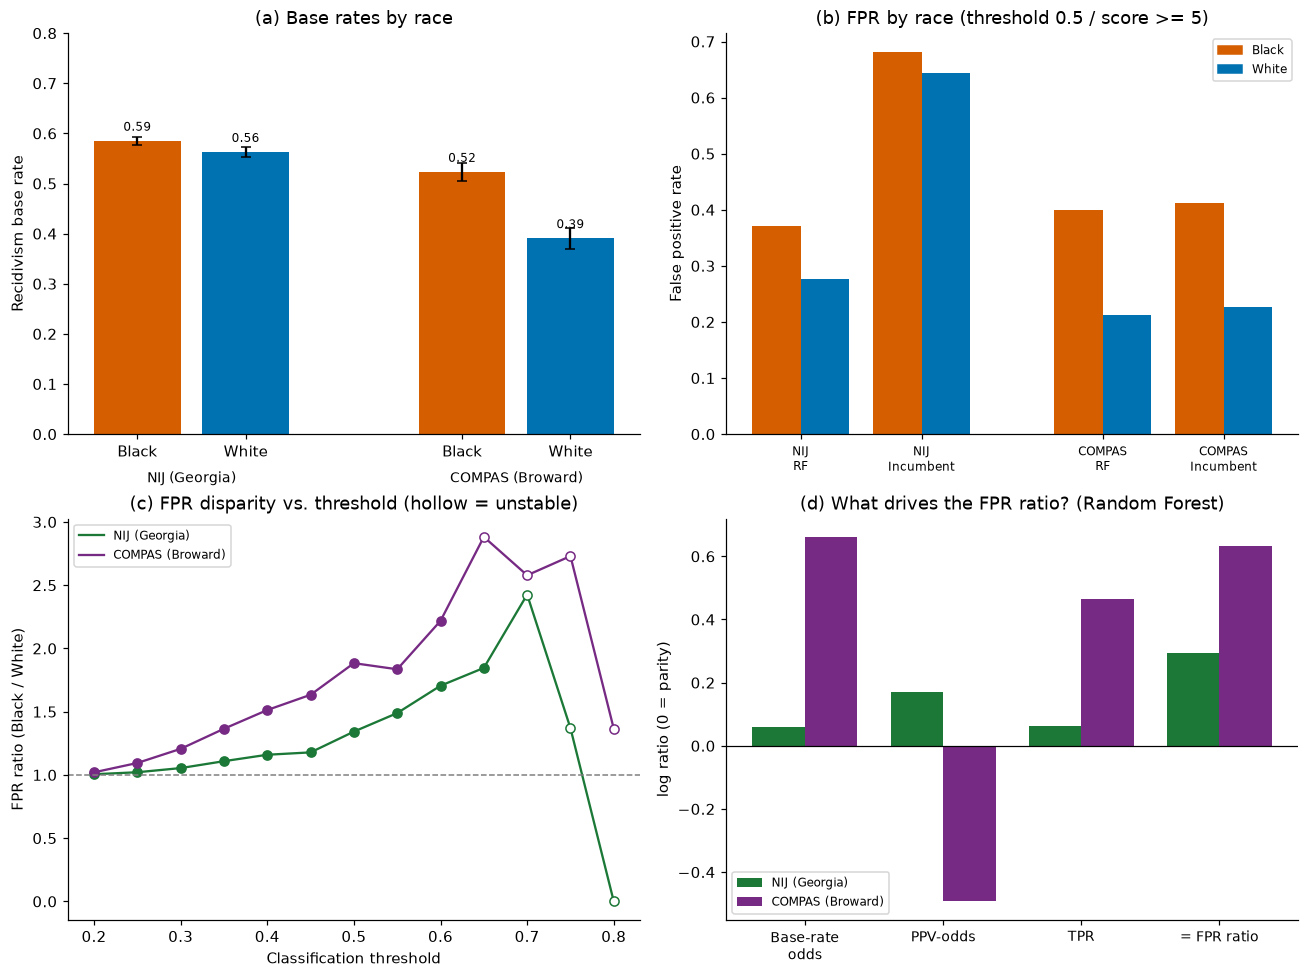

In [34]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
names = list(res)

# (a) base rates by race
ax = axes[0, 0]
xpos, labels = [], []
for i, nm in enumerate(names):
    b_ = nij if nm.startswith("NIJ") else compas
    for j, g in enumerate(b_["groups"]):
        s_ = b_["y_all"][b_["race_all"] == g]
        lo, hi = wilson_ci(s_.sum(), len(s_)); m_ = s_.mean(); x_ = i * 3 + j
        ax.bar(x_, m_, color=COLORS[g], yerr=[[m_ - lo], [hi - m_]], capsize=3)
        ax.text(x_, m_ + 0.02, f"{m_:.2f}", ha="center", fontsize=8)
        xpos.append(x_); labels.append(f"{'Black' if j == 0 else 'White'}")
ax.set_xticks(xpos); ax.set_xticklabels(labels)
for i, nm in enumerate(names):
    ax.text(i * 3 + 0.5, -0.12, nm, ha="center", fontsize=9, transform=ax.get_xaxis_transform())
ax.set_ylabel("Recidivism base rate"); ax.set_ylim(0, 0.8); ax.set_title("(a) Base rates by race")

# (b) FPR by race: RF and incumbent
ax = axes[0, 1]
x_ = 0; xt, xl = [], []
for nm in names:
    s_ = res[nm]
    for tag, lab in [("rf", "RF"), ("inc", "Incumbent")]:
        ax.bar(x_ - 0.2, s_[f"{tag}_fpr_b"], width=0.4, color=COLORS["BLACK"])
        ax.bar(x_ + 0.2, s_[f"{tag}_fpr_w"], width=0.4, color=COLORS["WHITE"])
        xt.append(x_); xl.append(f"{nm.split(' ')[0]}\n{lab}"); x_ += 1
    x_ += 0.5
ax.set_xticks(xt); ax.set_xticklabels(xl, fontsize=8); ax.set_ylabel("False positive rate")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COLORS["BLACK"]), plt.Rectangle((0, 0), 1, 1, color=COLORS["WHITE"])],
          labels=["Black", "White"], fontsize=8); ax.set_title("(b) FPR by race (threshold 0.5 / score >= 5)")

# (c) FPR ratio vs threshold
ax = axes[1, 0]
for nm, col in zip(names, ["#1b7837", "#762a83"]):
    sw_ = res[nm]["sweep"]; st_ = sw_["Stable"]
    ax.plot(sw_["Threshold"], sw_["FPR ratio"], "-", color=col, label=nm)
    ax.plot(sw_.loc[st_, "Threshold"], sw_.loc[st_, "FPR ratio"], "o", color=col)
    ax.plot(sw_.loc[~st_, "Threshold"], sw_.loc[~st_, "FPR ratio"], "o", mfc="white", color=col)
ax.axhline(1.0, color="grey", ls="--", lw=1); ax.set_xlabel("Classification threshold"); ax.set_ylabel("FPR ratio (Black / White)")
ax.set_title("(c) FPR disparity vs. threshold (hollow = unstable)"); ax.legend(fontsize=8)

# (d) Chouldechova decomposition (log scale) for the RF
ax = axes[1, 1]
comp_names = ["Base-rate odds ratio", "PPV-odds ratio", "TPR ratio", "FPR ratio (observed)"]
w_ = 0.38
for k, (nm, col) in enumerate(zip(names, ["#1b7837", "#762a83"])):
    vals = [np.log(res[nm][f"rf_ch_{c}"]) for c in comp_names]
    ax.bar(np.arange(4) + (k - 0.5) * w_, vals, width=w_, color=col, label=nm)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(range(4)); ax.set_xticklabels(["Base-rate\nodds", "PPV-odds", "TPR", "= FPR ratio"], fontsize=9)
ax.set_ylabel("log ratio (0 = parity)"); ax.set_title("(d) What drives the FPR ratio? (Random Forest)"); ax.legend(fontsize=8)
plt.tight_layout(); savefig("fig12_cross_dataset_comparison"); plt.show()

## 12. Summary of Findings (auto-generated)

The numbers below are produced by the code above, so they always match the tables and figures of the run that produced them. Copy them into the manuscript from here or from `nij_outputs/tables/`.

In [35]:
d_rf  = disparity[disparity["Model"] == RF_LABEL].set_index("Metric")
d_inc = disparity[disparity["Model"] == INC_LABEL].set_index("Metric")
ci = lambda d, m: f"{d.loc[m,'Estimate']:.2f}x [95% CI {d.loc[m,'CI low']:.2f}, {d.loc[m,'CI high']:.2f}]"
top3 = ", ".join(f"{k} ({v:.3f})" for k, v in mean_abs_shap.head(3).items())
dtop = decomp.index[0]

lines = []
lines.append(f"1. SAMPLE: N = {len(df):,} Georgia parolees ({100*(race==G1).mean():.1f}% Black); 3-year re-arrest rate = {y.mean():.3f} "
             f"(Black {br[G1]:.3f}, White {br[G2]:.3f}; gap {100*(br[G1]-br[G2]):+.1f} pp, chi-square p = {p_chi:.1e}).")
lines.append(f"2. PERFORMANCE ({PRIMARY_SPEC} spec, test n = {len(y_test):,}): {RF_LABEL.split(' (')[0]} AUC = {table2.iloc[0]['AUC']:.3f}, "
             f"{GB_LABEL.split(' (')[0]} AUC = {table2.iloc[1]['AUC']:.3f}, Georgia risk score AUC = {table2.iloc[2]['AUC']:.3f}. "
             f"History-only RF AUC = {table_specs.loc['History','RF AUC']:.3f}. 5-fold CV AUC (RF, {PRIMARY_SPEC}) = "
             f"{cv_scores[(PRIMARY_SPEC, 'Random Forest')].mean():.3f} +/- {cv_scores[(PRIMARY_SPEC, 'Random Forest')].std():.3f}.")
lines.append(f"3. SHAP: top inputs by mean |SHAP| = {top3}. Functional-form check: " +
             "; ".join(f"{k}: curves correlate r = {v['correlation of the two curves']:.2f}, max cell difference = {v['max |difference| (cells with n>=30 in both groups)']:.3f}"
                       for k, v in functional_form.items()) + ".")
lines.append(f"4. SHAP GAP DECOMPOSITION: mean predicted risk gap ({G1} - {G2}) = {total_gap:+.3f}; largest single contributor = {dtop} "
             f"({decomp.loc[dtop,'Contribution to gap']:+.3f}, {decomp.loc[dtop,'Share of gap (%)']:.0f}% of the gap).")
lines.append(f"5. FAIRNESS AT THE DEFAULT THRESHOLD: RF FPR ratio = {ci(d_rf,'FPR ratio')}, RF FNR ratio = {ci(d_rf,'FNR ratio')}; "
             f"Georgia score (>= {INC_CUTOFF}) FPR ratio = {ci(d_inc,'FPR ratio')}, FNR ratio = {ci(d_inc,'FNR ratio')}.")
lines.append("6. UNAWARENESS DIAGNOSTIC (RF FPR ratio by specification): " +
             "; ".join(f"{k} = {float(v):.2f}" for k, v in spec_audit["FPR ratio [95% CI]"].str.split(" ").str[0].items()) + ".")
lines.append(f"7. CALIBRATION: mean |calibration gap| = {cal_gap_rf[G1]:.3f} ({G1}) vs {cal_gap_rf[G2]:.3f} ({G2}) for the RF (6 quantile bins).")
lines.append(f"8. THRESHOLDS: RF FPR ratio ranges {sweep.loc[sweep['Stable'],'FPR ratio'].min():.2f}x - {sweep.loc[sweep['Stable'],'FPR ratio'].max():.2f}x "
             f"across stable thresholds 0.20-0.80 (unstable: {sweep.loc[~sweep['Stable'],'Threshold'].tolist() or 'none'}).")
lines.append(f"9. ROBUSTNESS: ten random splits give RF AUC {seed_summary.loc['RF AUC','mean']:.3f} (SD {seed_summary.loc['RF AUC','std']:.3f}) and "
             f"RF FPR ratio {seed_summary.loc['RF FPR ratio','mean']:.2f} (range {seed_summary.loc['RF FPR ratio','min']:.2f}-{seed_summary.loc['RF FPR ratio','max']:.2f}).")
if "COMPAS (Broward)" in res:
    a, c_ = res["NIJ (Georgia)"], res["COMPAS (Broward)"]
    lines.append(f"10. NIJ vs COMPAS: base-rate gap {a['base_gap_pp']:+.1f} pp vs {c_['base_gap_pp']:+.1f} pp; key prior-record SMD {a['prior_smd']:+.2f} vs {c_['prior_smd']:+.2f}; "
                 f"RF FPR ratio {a['rf_FPR ratio']:.2f} vs {c_['rf_FPR ratio']:.2f}; incumbent FPR ratio {a['inc_FPR ratio']:.2f} vs {c_['inc_FPR ratio']:.2f}; "
                 f"base-rate odds ratio component {a['rf_ch_Base-rate odds ratio']:.2f} vs {c_['rf_ch_Base-rate odds ratio']:.2f}.")
print("\n\n".join(lines))
with open(OUT / "summary_of_findings.txt", "w") as fh:
    fh.write("\n\n".join(lines))

1. SAMPLE: N = 25,360 Georgia parolees (57.4% Black); 3-year re-arrest rate = 0.576 (Black 0.585, White 0.563; gap +2.2 pp, chi-square p = 3.8e-04).

2. PERFORMANCE (Full spec, test n = 7,608): Random Forest AUC = 0.779, XGBoost AUC = 0.815, Georgia risk score AUC = 0.599. History-only RF AUC = 0.708. 5-fold CV AUC (RF, Full) = 0.782 +/- 0.007.

3. SHAP: top inputs by mean |SHAP| = Percent_Days_Employed (0.067), Gang_Affiliated (0.030), _v1 (0.030). Functional-form check: Prior_Arrest_Episodes_Felony: curves correlate r = 1.00, max cell difference = 0.002; Percent_Days_Employed: curves correlate r = 1.00, max cell difference = 0.004.

4. SHAP GAP DECOMPOSITION: mean predicted risk gap (BLACK - WHITE) = +0.023; largest single contributor = Percent_Days_Employed (+0.016, 68% of the gap).

5. FAIRNESS AT THE DEFAULT THRESHOLD: RF FPR ratio = 1.34x [95% CI 1.21, 1.52], RF FNR ratio = 0.83x [95% CI 0.76, 0.93]; Georgia score (>= 5) FPR ratio = 1.06x [95% CI 1.01, 1.11], FNR ratio = 0.88x [9

### 12.1 Limitations to state in the manuscript

* **Population and selection.** The NIJ file covers people *released from Georgia prisons to parole supervision*; it is neither a pretrial population (COMPAS) nor all releases. Findings do not automatically generalize to other jurisdictions or release routes.
* **Outcome measurement.** Recidivism is *re-arrest*, which depends on policing and enforcement intensity as well as behavior; the same caveat applies to the COMPAS outcome and to prior-arrest inputs.
* **Temporal ordering of supervision-period variables.** Employment, drug-test, violation and program variables are recorded during supervision. Confirm against the NIJ data dictionary whether they are measured before the outcome window; the *History* specification is the release-time check.
* **Two race categories.** The public NIJ file contains only Black and White; no statement about other groups is possible. Race in the NIJ file is as recorded by the agency.
* **Incumbent is not COMPAS.** The benchmark is the Georgia supervision score; its cut-off (>= 5) mirrors the COMPAS convention but is an analytic choice (see Section 9.1 for all cut-offs).
* **Probability scale.** Class-balanced Random Forests return scores on a re-weighted scale; calibration statements apply to the scores as produced, as in the COMPAS manuscript.
* **Interval estimates.** The CV interval is approximate (folds are not independent). Bootstrap intervals in Sections 7 and 11 capture test-set sampling error for a fixed trained model, not training-set variability; Section 10 addresses the latter.
* **Anonymized columns.** `_v1`-`_v4` have anonymized headers in the public file and are treated as generic prior-record fields.
* **Multiple specifications.** Four specifications are reported; state the primary specification (`PRIMARY_SPEC`) in advance and treat the others as sensitivity analyses.

In [36]:
meta = {"run_timestamp_utc": pd.Timestamp.now("UTC").isoformat(timespec="seconds"),
        "python": sys.version.split()[0], "platform": platform.platform(),
        "numpy": np.__version__, "pandas": pd.__version__, "shap": shap.__version__,
        "sklearn": __import__("sklearn").__version__, "xgboost": (__import__("xgboost").__version__ if XGB_AVAILABLE else "NOT AVAILABLE (fallback used)"),
        "config": {"SEED": SEED, "TEST_SIZE": TEST_SIZE, "THRESHOLD": THRESHOLD, "INC_CUTOFF": INC_CUTOFF, "N_BOOT": N_BOOT,
                   "PRIMARY_SPEC": PRIMARY_SPEC, "INCLUDE_GENDER": INCLUDE_GENDER},
        "analytic_sample_n": int(len(df))}
with open(OUT / "run_metadata.json", "w") as fh:
    json.dump(meta, fh, indent=2)
print(json.dumps(meta, indent=2))
print("\nSaved tables:", len(list((OUT / 'tables').glob('*.csv'))), "| figures:", len(list((OUT / 'figures').glob('*.png'))), "->", OUT.resolve())

{
  "run_timestamp_utc": "2026-10-03T12:29:15+00:00",
  "python": "3.12.3",
  "platform": "Windows-10-10.0.19045-SP0",
  "numpy": "2.5.2",
  "pandas": "3.0.5",
  "shap": "0.52.0",
  "sklearn": "1.8.0",
  "xgboost": "3.4.1",
  "config": {
    "SEED": 42,
    "TEST_SIZE": 0.3,
    "THRESHOLD": 0.5,
    "INC_CUTOFF": 5,
    "N_BOOT": 1000,
    "PRIMARY_SPEC": "Full",
    "INCLUDE_GENDER": true
  },
  "analytic_sample_n": 25360
}

Saved tables: 24 | figures: 13 -> C:\Users\hp\Desktop\Academic Articles\NIJ Recidivism Forecasting Challenge\NIJ (National Institute of Justice) Recidivism Challenge\nij_outputs


## References

- Andrews, D. A., & Bonta, J. (2010). *The Psychology of Criminal Conduct* (5th ed.). Anderson Publishing.
- Angwin, J., Larson, J., Mattu, S., & Kirchner, L. (2016, May 23). Machine Bias. *ProPublica*.
- Barocas, S., Hardt, M., & Narayanan, A. (2023). *Fairness and Machine Learning: Limitations and Opportunities*. MIT Press.
- Chouldechova, A. (2017). Fair prediction with disparate impact: A study of bias in recidivism prediction instruments. *Big Data, 5*(2), 153-163.
- Dieterich, W., Mendoza, C., & Brennan, T. (2016). *COMPAS risk scales: Demonstrating accuracy equity and predictive parity*. Northpointe Inc. Research Department.
- Dressel, J., & Farid, H. (2018). The accuracy, fairness, and limits of predicting recidivism. *Science Advances, 4*(1), eaao5580.
- Gottfredson, M. R., & Hirschi, T. (1990). *A General Theory of Crime*. Stanford University Press.
- Kleinberg, J., Mullainathan, S., & Raghavan, M. (2017). Inherent trade-offs in the fair determination of risk scores. *ITCS 2017* (LIPIcs, Vol. 67, 43:1-43:23).
- Larson, J., Mattu, S., Kirchner, L., & Angwin, J. (2016, May 23). How We Analyzed the COMPAS Recidivism Algorithm. *ProPublica*.
- Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *NeurIPS 2017*, 4765-4774.
- National Institute of Justice. (2021). *Recidivism Forecasting Challenge* [Data set and documentation]. Office of Justice Programs, U.S. Department of Justice.